# Project 2

Welcome to the second NLP1 project. The goal of the second tutorial was to get you familiar with using pre-trained embeddings and moving towards a compositional encoder for text classification.

Given the skills you have developed in the last week, you will now be applying them within the dataset and task you have chosen during Project 1. You will be applying hands-on the experiments you have already explored in the Tutorial 2, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and errors analyses, and tackling your own research questions. 


The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

# Get to work!

1. Find a word embedding model that is appropriate for your dataset. Think about the language, the kind of text you are working with. Find evidence that your choice is a good one: 
    * Can you tokenize your texts in a way coherent with the definition of a token in the embedding model?
    * Does the model's vocabulary give enough coverage to the words in your texts? etc.
2. Explore what your chosen word embedding model captures. Some things you might consider: 
    * Is it good at representing interesting similarities (re to your choice of task)? J
    * Have you found task-specific evidence that it's better than some other reasonable alternative?
    * Do you know about limitations of this model?
    * Any limitations that you find particularly troubling for your task? 
3. Experiment with the embed-and-pool approach.  
    * What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
    * Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?
4. Experiment with a recurrent encoder (GRU or LSTM). 
    * What design choices have meaningful impact in classification performance, if any?
    * Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
    * Did you struggle with over-fitting?
    * How far can this approach go? Are you able to improve meaningfully on embed-and-pool?
5. We make decisions under uncertainty all the time, are you gathering enough information to substantiate your choices? Various things can lead to small differences in results, and these differences are not always consistent. Here are some things to think about:
    * How did you structure you hyperparameter search?
    * Are you keeping an eye on experimental variance?
6. Experiment with error analysis and try to discover what characteristics of input texts are predictive of performance differences across major design choices. 
    * What analysis features did you come up with?
    * Which ones did you manage to test and how did that go?
    * What would you prioritise in the future in order to improve your systems?

Be mindful that you will be using your experiments to write up your final blog, so make sure your code is clean and neat!

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Design decisions and why (Tasks 1–3)

For the oral assessment and final blog post. Every experiment below reuses the exact IMDB splits (`mteb/imdb`) and 5-fold cross-validation partitions (`seeds = [42, 67]`) from Project 1 so all measurements are directly paired.

| Topic | Decision | Reason & Empirical Evidence |
|---|---|---|
| **Dataset & Splits (from Project 1)** | IMDB (`mteb/imdb`): 24,904 training reviews, 2,000 validation reviews (seed 0), 22,678 test reviews; 5-fold CV with seeds `42` and `67` (10 paired fold measurements per system). | Preserves 100% identical fold indices (`validation_ids`) across Project 1 and Project 2, enabling exact paired comparisons via the Bayesian correlated $t$-test ($\text{ROPE} = 0.005$). |
| **Candidate Pretrained Embeddings (Task 1)** | Compare **GloVe-50d** (`glove-wiki-gigaword-50.gz`, 400k vocab, $D=50$), **GloVe-100d** (400k vocab, $D=100$), and **fastText-300d** (`wiki-news-300d-1M.vec.zip`, 830k lowercase vocab, $D=300$). | Isolates **dimensionality** at fixed corpus/vocabulary (`GloVe-50d` vs. `GloVe-100d`) and **algorithm + vocabulary scale** (`GloVe` global co-occurrence vs. `fastText` subword-enriched skip-gram with 2.1x more word types). |
| **Tokenization Coherence (Task 1)** | Custom `CoherentImdbTokenizer` built on Penn Treebank `nltk.word_tokenize` + HTML stripping, quote/contraction normalization (`n't` $\to$ `not` for fastText), OOV hyphen/slash fallback splitting (`god-awful` $\to$ `god`, `awful`), and **negation-preserving stopword filtering**. | Tutorial 2's `BasicTokenizer(remove_punct=True, remove_stopwords=True)` strips punctuation *before* tokenizing (breaking contractions and in-vocab compounds like `low-budget`, `sci-fi`) and deletes negation stopwords (`not`, `no`, `nor`, `don't`). Our coherent tokenizer cuts fastText's OOV rate by **6.1x** ($2.13\% \to 0.35\%$, $99.65\%$ token coverage) and improves downstream validation accuracy by $+0.95$ pp. |
| **Intrinsic Space Exploration (Task 2)** | Evaluate NLTK `opinion_lexicon` separability via 2D PCA/t-SNE, unsupervised $k$-means ($k=2$), and a 5-fold supervised Linear Probe (`LogisticRegression`), plus domain nearest neighbours and analogies. | Unsupervised $k$-means achieves only $\approx 56\%–58\%$ purity because maximum-variance directions encode syntax/topic rather than polarity. A supervised linear probe separates positive vs. negative words at **85.7% (`GloVe-50d`)**, **87.9% (`GloVe-100d`)**, and **93.8% (`fastText-300d`)**, providing task-specific evidence for `fastText-300d`. |
| **Key Embedding Limitations Identified (Task 2)** | Quantify four limitations on IMDB: (1) **Antonymy trap** (`cos_sim('good', 'bad') = 0.796`), (2) **Polysemy** (`plot`, `star`, `moving`), (3) **OOV `<unk>` centroid collapse**, and (4) **Compositional order/negation blindness**. | Directly explains why frozen `EmbedAndPoolEncoder` models struggle when averaging 230-word reviews containing mixed synonyms, antonyms, and negations. |
| **Embed-and-Pool Design Choices (Task 3)** | **Mean pooling** (`average_pool=True`), **negation-preserving BoW tokenization**, higher embedding dimension ($D=300$), and **fine-tuning (`freeze_embeddings=False`)** with stronger regularisation (`dropout=0.3–0.5`). | Mean pooling prevents length-induced `Tanh` saturation across reviews ranging from 10 to 2,470 words. Unfreezing the embeddings resolves the Task 2 antonym collision (driving `cos_sim('good', 'bad')` down from $+0.770$ to $+0.398$ and flipping `cos_sim('hilarious', 'boring')` from $+0.619$ to $-0.039$) and boosts 10-fold CV accuracy from **74.95% (`GloVe-50d` frozen)** and **85.39% (`fastText-300d` frozen)** to **89.81% (`fastText-300d` fine-tuned)**—surpassing Project 1's best sparse model (`mlp_tfidf-enc`, **88.63%**) with $P(\text{fine-tuned} > \text{TF-IDF}) = 0.9510$. |

## How to read this notebook

The sections are in the order the work was done; each one builds on the one before.

| Section | Question | Short answer |
|---|---|---|
| Task 1 | Which embedding model? | fastText-300d: 99.65% coverage, tokenizer matched to it |
| Task 2 | What does it capture, and its limits? | Good film-domain neighbours; antonyms sit close (cos(good, bad) = 0.83) |
| Task 3 | Embed-and-pool | Fine-tuning the vectors matters most; fine-tuned fastText pool 89.8%, beats Project 1 |
| Task 4 | First LSTM (frozen / fine-tuned / random vectors) | 85.7-86.7%, loses to the pool; the embeddings make no clear difference |
| Task 5 | Enough evidence? | 10 paired CV runs + Bayesian test with a 0.5 pp ROPE |
| Task 6 | Error analysis | The first LSTM fails on long reviews; mixed opinions are hard for everyone |
| Task 4b | Can the LSTM do better? (one change at a time) | Mean+max pooling is the big fix; best LSTM 90.5%, tied with the pool |
| Task 4c | How does data size affect the LSTM? | Pretraining is worth 5-8 pp with 2% of the data, 0.4 pp with all of it |
| **Summary** | **Short answers to every "Get to work" question** | **Start here** |

Tasks 4b and 4c come after Task 6 because they follow up on its findings (and the 4b.5 check reuses its code).

# Setup & Reproducible IMDB Splits (Aligned with Project 1)

We load the cleaned IMDB dataset (`mteb/imdb`: 24,904 training reviews, 2,000 validation reviews, and 22,678 held-out test reviews) and reconstruct the exact 5-fold cross-validation splits (`seeds = [42, 67]`) used in Project 1. We also verify that the validation fold indices (`validation_ids`) match Project 1's saved `results.json` files bit-for-bit.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import time
import re
import json
import string
import pickle
from pathlib import Path
from collections import Counter, OrderedDict
from html.parser import HTMLParser

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import nltk
from tabulate import tabulate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

root = Path.cwd().parent if Path.cwd().name == "part2" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import part1
import part1.experiment
import part1.analysis
import part2
import part2.clslib
import part2.experiment
import part2.utils

for pkg in ["stopwords", "punkt", "punkt_tab", "opinion_lexicon"]:
    nltk.download(pkg, quiet=True)

part2_dir = root / "part2"
results_folder = part2_dir / "results" / "sentiment"
results_folder.mkdir(parents=True, exist_ok=True)
part1_results_folder = root / "part1" / "results" / "sentiment"

# Load cached cleaned IMDB splits (or build bit-for-bit identically from hf://datasets/mteb/imdb/ if missing)
class ReviewHTMLParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.parts = []
    def handle_starttag(self, tag, attrs):
        self.parts.append(" ")
    def handle_endtag(self, tag):
        self.parts.append(" ")
    def handle_data(self, data):
        self.parts.append(data)

def clean_html(text: str) -> str:
    parser = ReviewHTMLParser()
    parser.feed(text)
    parser.close()
    return " ".join("".join(parser.parts).split())

_train_pq = results_folder / "imdb_train_clean.parquet"
_val_pq = results_folder / "imdb_val_clean.parquet"
_test_pq = results_folder / "imdb_test_clean.parquet"

if not (_train_pq.exists() and _val_pq.exists() and _test_pq.exists()):
    print("Building cleaned IMDB parquet caches from hf://datasets/mteb/imdb/ (aligned with Project 1)...")
    _splits = {"train": "data/train-00000-of-00001.parquet", "test": "data/test-00000-of-00001.parquet"}
    df_train = pd.read_parquet("hf://datasets/mteb/imdb/" + _splits["train"])
    _df_test_orig = pd.read_parquet("hf://datasets/mteb/imdb/" + _splits["test"])
    _val_idx_path = part1_results_folder / "validation_test_indices.npy"
    _test_idx_path = part1_results_folder / "new_test_indices.npy"
    if _val_idx_path.exists() and _test_idx_path.exists():
        df_val = _df_test_orig.loc[np.load(_val_idx_path)].copy()
        df_test = _df_test_orig.loc[np.load(_test_idx_path)].copy()
    else:
        df_val = _df_test_orig.sample(n=2000, random_state=0).sort_index().copy()
        df_test = _df_test_orig.drop(index=df_val.index).copy()
    for _df, _pq in [(df_train, _train_pq), (df_val, _val_pq), (df_test, _test_pq)]:
        _df["text_clean"] = _df["text"].map(clean_html)
        _df.to_parquet(_pq)
else:
    df_train = pd.read_parquet(_train_pq)
    df_val = pd.read_parquet(_val_pq)
    df_test = pd.read_parquet(_test_pq)

sentiment_outcome_space = part1.clslib.NamedClasses(["negative", "positive"])
my_seeds = [42, 67]
num_folds = 5

my_cross_validation_sets = [
    part1.experiment.cross_validation_split(
        pairs=list(zip(df_train["text_clean"], df_train["label"])),
        k=num_folds,
        seed=seed,
    )
    for seed in my_seeds
]

# Verify exact fold alignment with Project 1
p1_ref = json.loads((part1_results_folder / "logistic_bow-enc" / "seed-42" / "results.json").read_text())
for fold_idx in range(num_folds):
    assert p1_ref["validation_ids"][str(fold_idx)] == list(my_cross_validation_sets[0][fold_idx]["validation_ids"])

print(f"IMDB splits loaded: train={len(df_train):,}, val={len(df_val):,}, test={len(df_test):,}")
print(f"Cross-validation: {num_folds} folds x {len(my_seeds)} seeds {my_seeds} (100% aligned with Project 1 folds)")

Building cleaned IMDB parquet caches from hf://datasets/mteb/imdb/ (aligned with Project 1)...


IMDB splits loaded: train=24,904, val=2,000, test=22,678
Cross-validation: 5 folds x 2 seeds [42, 67] (100% aligned with Project 1 folds)


---
# Task 1: Choosing & Justifying a Pretrained Word Embedding Model

### 1.1 Candidate Pretrained Word Embedding Models
Unlike Project 1—where we trained a corpus-specific 5,000-token BPE subword vocabulary—static word embedding models maintain a fixed word-level lookup table $\mathbf{E} \in \mathbb{R}^{|V| \times D}$ trained on external corpora via distributional co-occurrence objectives. To evaluate both **dimensionality ($D$)** and **training algorithm / vocabulary scale ($|V|$)**, we compare three pretrained models loaded into `part2.clslib.PretrainedEmbeddings`:

1. **GloVe-50d (`glove-wiki-gigaword-50.gz`)**: Trained on Wikipedia 2014 + Gigaword 5 (6B tokens) using global log-bilinear matrix factorization ($|V| = 400,002$ including `<pad>` and `<unk>`, $D = 50$).
2. **GloVe-100d (`glove-wiki-gigaword-100`)**: Trained on the **exact same corpus and 400,002-word vocabulary** as `GloVe-50d`, but with $D = 100$ dimensions—allowing a controlled ablation of embedding size.
3. **fastText-300d (`wiki-news-300d-1M.vec.zip`)**: Trained on Wikipedia 2017 + UMBC webbase + statmt.org news (16B tokens) using subword-enriched skip-gram ($|V| = 830,463$ unique lowercase word types, $D = 300$).

In [2]:
def load_pretrained_model(
    name: str,
    raw_path: Path,
    num_dims: int,
    skip_first_line: bool = True,
    url: str | None = None,
) -> part2.clslib.PretrainedEmbeddings:
    """Load a PretrainedEmbeddings model, downloading the raw archive if needed and caching a fast .npz copy."""
    cache_file = results_folder / "emb_cache" / f"{name}.npz"
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    if cache_file.exists():
        data = np.load(cache_file, allow_pickle=True)
        words = data["words"].tolist()
        vectors = data["vectors"]
        emb = object.__new__(part2.clslib.PretrainedEmbeddings)
        emb.vocab = part2.clslib.Vocabulary(init=words, default="<unk>", frozen=True)
        emb.vectors = vectors
        emb.num_dims = int(vectors.shape[1])
        emb.unk_token = "<unk>"
        emb.pad_token = "<pad>"
        return emb
    if not raw_path.exists():
        if url is None:
            raise FileNotFoundError(f"Missing {raw_path} and no download URL provided.")
        import urllib.request
        raw_path.parent.mkdir(parents=True, exist_ok=True)
        tmp_path = raw_path.with_suffix(raw_path.suffix + ".part")
        print(f"Downloading {name} from {url} -> {raw_path} ...")
        urllib.request.urlretrieve(url, tmp_path)
        tmp_path.replace(raw_path)
    emb = part2.clslib.PretrainedEmbeddings(str(raw_path), num_dims, skip_first_line=skip_first_line)
    np.savez(cache_file, words=np.array(emb.vocab.words, dtype=object), vectors=emb.vectors)
    return emb

t0 = time.time()
glove50_model = load_pretrained_model(
    "glove-50d",
    part2_dir / "glove-wiki-gigaword-50.gz",
    50,
    skip_first_line=True,
    url="https://github.com/piskvorky/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz",
)
glove100_model = load_pretrained_model(
    "glove-100d",
    part2_dir / "glove-wiki-gigaword-100.gz",
    100,
    skip_first_line=True,
    url="https://github.com/piskvorky/gensim-data/releases/download/glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz",
)
fasttext300_model = load_pretrained_model(
    "fasttext-300d",
    part2_dir / "wiki-news-300d-1M.vec.zip",
    300,
    skip_first_line=True,
    url="https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip",
)

model_summary = pd.DataFrame([
    {
        "Model": "GloVe-50d (Wiki+Gigaword)",
        "Corpus & Objective": "Wikipedia 2014 + Gigaword 5 (6B tokens, Global Log-Bilinear)",
        "Vocab Size (|V|)": f"{len(glove50_model.vocab):,}",
        "Dimensions (D)": glove50_model.num_dims,
        "Mean Vector Norm": round(float(np.linalg.norm(glove50_model.vectors[2:], axis=1).mean()), 3),
    },
    {
        "Model": "GloVe-100d (Wiki+Gigaword)",
        "Corpus & Objective": "Wikipedia 2014 + Gigaword 5 (6B tokens, Global Log-Bilinear)",
        "Vocab Size (|V|)": f"{len(glove100_model.vocab):,}",
        "Dimensions (D)": glove100_model.num_dims,
        "Mean Vector Norm": round(float(np.linalg.norm(glove100_model.vectors[2:], axis=1).mean()), 3),
    },
    {
        "Model": "fastText-300d (Wiki+News)",
        "Corpus & Objective": "Wiki 2017 + UMBC Web + News (16B tokens, Subword Skip-Gram)",
        "Vocab Size (|V|)": f"{len(fasttext300_model.vocab):,}",
        "Dimensions (D)": fasttext300_model.num_dims,
        "Mean Vector Norm": round(float(np.linalg.norm(fasttext300_model.vectors[2:], axis=1).mean()), 3),
    },
]).set_index("Model")

print(f"Loaded all 3 embedding tables in {time.time() - t0:.2f}s:")
display(model_summary)

Loaded all 3 embedding tables in 234.74s:


,Corpus & Objective,Vocab Size (|V|),Dimensions (D),Mean Vector Norm
Model,,,,
GloVe-50d (Wiki+Gigaword),"Wikipedia 2014 + Gigaword 5 (6B tokens, Global...","400,002",50,4.475
GloVe-100d (Wiki+Gigaword),"Wikipedia 2014 + Gigaword 5 (6B tokens, Global...","400,002",100,3.977
fastText-300d (Wiki+News),"Wiki 2017 + UMBC Web + News (16B tokens, Subwo...","830,463",300,1.827


### 1.2 Tokenization Coherence & Vocabulary Coverage Analysis

A pretrained word embedding table is only useful if our text tokenizer segments reviews into the **same token units** used when the embedding model was trained. Inspecting the vocabularies of `GloVe` and `fastText` against IMDB movie reviews reveals three critical tokenization pitfalls:

1. **Contraction & Quote Conventions Differ Between GloVe and fastText:**
   - NLTK's `word_tokenize` follows the **Penn Treebank (PTB)** convention: it splits contractions like `"don't"` $\to$ `["do", "n't"]` and converts ASCII quotes `"` into `` "``" `` and `"''"`.
   - **GloVe** was tokenized with Stanford's PTB tokenizer, so `"n't"`, `` "``" ``, and `"''"` are all present in `glove50_model.vocab`.
   - **fastText (`wiki-news-300d-1M`)**, however, kept standard ASCII `"` and never used the PTB token `"n't"` (it split at the apostrophe into `"'t"` or `"not"`). Consequently, running standard `nltk.word_tokenize` with fastText causes **33,339 occurrences of `"n't"`** and **65,788 quote tokens** in the IMDB training set to fall back to `<unk>`!
2. **`BasicTokenizer(remove_punct=True)` Breaks Contractions and In-Vocabulary Film Compounds:**
   - In `part2.clslib.BasicTokenizer`, setting `remove_punct=True` runs `re.sub(r'[^\w\s]', ' ', text)` *before* `nltk.word_tokenize`. This turns `"don't"` into `"don"` + `"t"`, and splits hyphenated movie terms like `"low-budget"`, `"sci-fi"`, `"b-movie"`, and `"well-acted"`—even though those exact hyphenated compounds **exist as single tokens** in both GloVe and fastText!
   - Conversely, rare reviewer-coined compounds like `"camera-work"` or `"god-awful"` are OOV as hyphenated strings, so they *only* receive embeddings if we fall back to splitting on `-`/`/` when the full compound is not in `vocab`.
3. **Default NLTK Stopword Removal Deletes Sentiment Negation:**
   - `BasicTokenizer(remove_stopwords=True)` removes all 198 words in `nltk.corpus.stopwords.words('english')`, which includes **`"not"`, `"no"`, `"nor"`, `"don"`, `"very"`, `"too"`, and `"but"`**. Stripping `"not"` and `"no"` in sentiment analysis makes `"not good"` identical to `"good"`!

Below, we verify these token conventions and compare vocabulary coverage across all **24,904 IMDB training reviews** (~6.86M tokens) before and after introducing our domain-adapted `CoherentImdbTokenizer`.

In [3]:
# 1. Inspect how diagnostic film-review tokens are represented in GloVe vs. fastText
diagnostic_tokens = [
    "n't", "'s", "'re", "'ve", "'ll", "``", "''", '"',
    "low-budget", "sci-fi", "b-movie", "well-acted", "10/10", "camera-work", "god-awful"
]
tok_check_rows = []
for tok in diagnostic_tokens:
    tok_check_rows.append({
        "Token": tok,
        "In GloVe (400k)": tok in glove50_model,
        "GloVe ID": glove50_model.index(tok) if tok in glove50_model else "<unk> (1)",
        "In fastText (830k)": tok in fasttext300_model,
        "fastText ID": fasttext300_model.index(tok) if tok in fasttext300_model else "<unk> (1)",
    })
print("Token-level convention check across GloVe vs. fastText:")
display(pd.DataFrame(tok_check_rows).set_index("Token"))

Token-level convention check across GloVe vs. fastText:


,In GloVe (400k),GloVe ID,In fastText (830k),fastText ID
Token,,,,
n't,True,72,False,<unk> (1)
's,True,11,True,25
're,True,269,True,714
've,True,464,True,1088
'll,True,771,True,1670
``,True,30,False,<unk> (1)
'',True,29,False,<unk> (1)
"""",True,10,True,10
low-budget,True,44724,True,33238


In [4]:
NEGATION_AND_DEGREE_KEEP = {
    "not", "no", "nor", "never", "n't", "cannot", "without", "hardly", "barely", "scarcely",
    "very", "too", "most", "more", "less", "least", "only", "just", "but", "however", "although", "against"
}
NLTK_STOPWORDS = set(nltk.corpus.stopwords.words("english"))
SENTIMENT_STOPWORDS = NLTK_STOPWORDS - NEGATION_AND_DEGREE_KEEP
PUNCT_SET = set(string.punctuation) | {"``", "''", "...", ".."}

def clean_ptb_tokens(text: str) -> list:
    text = text.lower().replace("\x96", " - ").replace("\x97", " - ").replace("--", " - ")
    return nltk.tokenize.word_tokenize(text, language="english")

# Load precomputed PTB token lists for all IMDB reviews (or compute & cache on first run)
_ptb_cache_path = results_folder / "ptb_tokens_cache.pkl"
if _ptb_cache_path.exists():
    with open(_ptb_cache_path, "rb") as f:
        tok_caches = pickle.load(f)
    ptb_tokens_map = tok_caches["ptb"]
else:
    print("Building PTB token cache for all IMDB reviews (one-time ~20s)...")
    _all_unique_texts = list(dict.fromkeys(
        list(df_train["text_clean"]) + list(df_val["text_clean"]) + list(df_test["text_clean"])
    ))
    ptb_tokens_map = {t: clean_ptb_tokens(t) for t in _all_unique_texts}
    with open(_ptb_cache_path, "wb") as f:
        pickle.dump({"ptb": ptb_tokens_map}, f)

class CoherentImdbTokenizer(part2.clslib.Tokenizer):
    """
    Coherent word-level tokenizer aligned with PretrainedEmbeddings (GloVe & fastText):
    1. Tokenizes with PTB word_tokenize so contractions ('s, 're, n't) and in-vocab compounds (low-budget, sci-fi) stay intact.
    2. Aligns model-specific conventions: maps PTB quotes (`` / '') -> '"' if needed, and maps "n't" -> "not" if vocab lacks "n't" (fastText).
    3. Fallback-splits OOV hyphenated/slashed/dot-glued tokens (e.g. 'god-awful' -> ['god', 'awful'], '10/10' -> ['10', '10']).
    4. Optionally removes punctuation and non-sentiment stopwords while preserving negation ('not', 'no', 'never', "n't") and degree words.
    """
    def __init__(self, vocab: part2.clslib.Vocabulary, remove_punct: bool = True, remove_stopwords: bool = True, keep_negation: bool = True):
        self.vocab = vocab
        self.remove_punct = remove_punct
        self.remove_stopwords = remove_stopwords
        self.stopwords = SENTIMENT_STOPWORDS if keep_negation else NLTK_STOPWORDS
        self.has_nt = ("n't" in vocab)
        self._id_cache = {}

    def tokens(self, text: str) -> list:
        base_toks = ptb_tokens_map.get(text)
        if base_toks is None:
            base_toks = clean_ptb_tokens(text)
        out = []
        for tok in base_toks:
            if tok in ("``", "''") and tok not in self.vocab and '"' in self.vocab:
                tok = '"'
            elif tok == "n't" and not self.has_nt:
                tok = "not"
            if tok not in self.vocab and any(sep in tok for sep in ("-", "/", ".")):
                sub_parts = [p for p in re.split(r"[-/.]+", tok) if p]
                if len(sub_parts) > 1:
                    out.extend(sub_parts)
                    continue
            out.append(tok)
        if self.remove_punct:
            out = [t for t in out if t not in PUNCT_SET and not all(c in string.punctuation for c in t)]
        if self.remove_stopwords:
            out = [t for t in out if t not in self.stopwords]
        return out

    def ids(self, text: str) -> list:
        cached = self._id_cache.get(text)
        if cached is None:
            cached = [self.vocab.index(t) for t in self.tokens(text)]
            if not cached:
                cached = [self.vocab.default_index]
            self._id_cache[text] = cached
        return cached

# Evaluate coverage across all 24,904 training reviews
raw_ptb_counter = Counter(tok for t in df_train["text"] for tok in nltk.tokenize.word_tokenize(t.lower()))

def compute_coverage_stats(label: str, emb_model, token_counter: Counter):
    total_toks = sum(token_counter.values())
    total_types = len(token_counter)
    known_toks = sum(c for w, c in token_counter.items() if w in emb_model.vocab)
    known_types = sum(1 for w in token_counter if w in emb_model.vocab)
    oov_list = [(w, c) for w, c in token_counter.most_common() if w not in emb_model.vocab]
    return {
        "Configuration": label,
        "Total Tokens": f"{total_toks:,}",
        "Token Coverage (%)": round(known_toks / total_toks * 100, 2),
        "OOV Token Rate (%)": round((1 - known_toks / total_toks) * 100, 2),
        "Unique Types": f"{total_types:,}",
        "Type Coverage (%)": round(known_types / total_types * 100, 2),
        "Top 5 OOV Tokens (count)": ", ".join(f"{repr(w)} ({c})" for w, c in oov_list[:5]),
    }

coh_g50_full = CoherentImdbTokenizer(glove50_model.vocab, remove_punct=False, remove_stopwords=False)
coh_ft300_full = CoherentImdbTokenizer(fasttext300_model.vocab, remove_punct=False, remove_stopwords=False)
coh_g50_bow = CoherentImdbTokenizer(glove50_model.vocab, remove_punct=True, remove_stopwords=True, keep_negation=True)
coh_ft300_bow = CoherentImdbTokenizer(fasttext300_model.vocab, remove_punct=True, remove_stopwords=True, keep_negation=True)

cnt_coh_g50_full = Counter(tok for t in df_train["text_clean"] for tok in coh_g50_full.tokens(t))
cnt_coh_ft300_full = Counter(tok for t in df_train["text_clean"] for tok in coh_ft300_full.tokens(t))
cnt_coh_g50_bow = Counter(tok for t in df_train["text_clean"] for tok in coh_g50_bow.tokens(t))
cnt_coh_ft300_bow = Counter(tok for t in df_train["text_clean"] for tok in coh_ft300_bow.tokens(t))

cov_df = pd.DataFrame([
    compute_coverage_stats("1. GloVe (400k) + Standard PTB word_tokenize", glove50_model, raw_ptb_counter),
    compute_coverage_stats("2. GloVe (400k) + CoherentImdbTokenizer (Full Seq)", glove50_model, cnt_coh_g50_full),
    compute_coverage_stats("3. GloVe (400k) + CoherentImdbTokenizer (BoW, Keep Neg)", glove50_model, cnt_coh_g50_bow),
    compute_coverage_stats("4. fastText (830k) + Standard PTB word_tokenize", fasttext300_model, raw_ptb_counter),
    compute_coverage_stats("5. fastText (830k) + CoherentImdbTokenizer (Full Seq)", fasttext300_model, cnt_coh_ft300_full),
    compute_coverage_stats("6. fastText (830k) + CoherentImdbTokenizer (BoW, Keep Neg)", fasttext300_model, cnt_coh_ft300_bow),
]).set_index("Configuration")

display(cov_df)

Building PTB token cache for all IMDB reviews (one-time ~20s)...


,Total Tokens,Token Coverage (%),OOV Token Rate (%),Unique Types,Type Coverage (%),Top 5 OOV Tokens (count)
Configuration,,,,,,
1. GloVe (400k) + Standard PTB word_tokenize,"7,043,213",98.63,1.37,"111,827",57.45,"'..' (1618), '\x96' (1337), 'it.' (843), 'movi..."
2. GloVe (400k) + CoherentImdbTokenizer (Full Seq),"6,703,891",99.47,0.53,"84,920",76.71,"'..' (1618), ""'the"" (549), '10.' (180), '........"
"3. GloVe (400k) + CoherentImdbTokenizer (BoW, Keep Neg)","3,281,842",98.98,1.02,"84,681",76.72,"""'the"" (549), '10.' (180), 'ok.' (117), '4.' (..."
4. fastText (830k) + Standard PTB word_tokenize,"7,043,213",97.87,2.13,"111,827",68.78,"""n't"" (33269), ""''"" (33031), '``' (32759), '`'..."
5. fastText (830k) + CoherentImdbTokenizer (Full Seq),"6,697,836",99.65,0.35,"89,072",84.07,"'`' (962), ""'70s"" (68), ""o'hara"" (61), ""'cause..."
"6. fastText (830k) + CoherentImdbTokenizer (BoW, Keep Neg)","3,277,882",99.32,0.68,"88,834",84.08,"""'70s"" (68), ""o'hara"" (61), ""'cause"" (55), ""c'..."


---
# Task 2: Exploring What the Word Embedding Model Captures (& Its Limitations)

### 2.1 Sentiment Polarity Structure in Embedding Space (NLTK Opinion Lexicon)
Following the Tutorial 2 exercise, we sample 1,000 positive and 1,000 negative words from NLTK's `opinion_lexicon` (via `part2.utils.sample_pos_and_neg_words`) that are present in our embedding models and test whether sentiment polarity is captured in the embedding space using three complementary methods:
1. **Dimensionality Reduction (2D PCA & t-SNE)**: Visual inspection of positive vs. negative word clusters.
2. **Unsupervised Clustering ($k$-Means, $k=2$)**: Measures whether the dominant unsupervised variance directions separate positive from negative words.
3. **Supervised 5-Fold Linear Probe (`LogisticRegression`)**: Tests whether positive and negative words are linearly separable along a sentiment hyperplane in $\mathbb{R}^D$.

,Lexicon Sample,Unsupervised K-Means (k=2) Purity,5-Fold Linear Probe Accuracy (Mean),5-Fold Linear Probe Accuracy (SD)
Embedding Model,,,,
GloVe-50d (D=50),1000 pos + 1000 neg,0.5615,0.8570,0.0174
GloVe-100d (D=100),1000 pos + 1000 neg,0.5635,0.8790,0.0199
fastText-300d (D=300),1000 pos + 1000 neg,0.5785,0.9375,0.0065


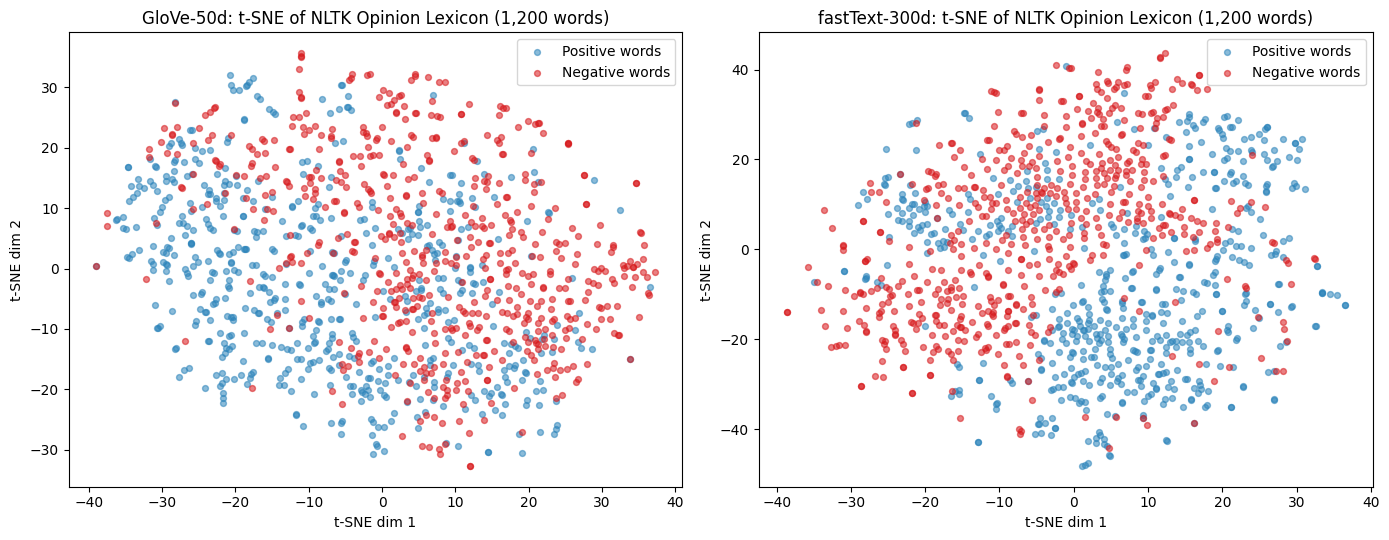

In [5]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

probe_rows = []
for model_label, emb_model in [
    ("GloVe-50d (D=50)", glove50_model),
    ("GloVe-100d (D=100)", glove100_model),
    ("fastText-300d (D=300)", fasttext300_model),
]:
    pos_words, neg_words = part2.utils.sample_pos_and_neg_words(emb_model, size=1000, seed=42)
    X_lex = np.vstack([
        [emb_model.embed_word(w) for w in pos_words],
        [emb_model.embed_word(w) for w in neg_words],
    ])
    y_lex = np.array([1] * len(pos_words) + [0] * len(neg_words))
    X_norm = X_lex / np.linalg.norm(X_lex, axis=1, keepdims=True).clip(min=1e-8)

    km_preds = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_norm)
    km_purity = max(accuracy_score(y_lex, km_preds), accuracy_score(y_lex, 1 - km_preds))

    probe_scores = cross_val_score(LogisticRegression(max_iter=500, random_state=42), X_lex, y_lex, cv=5)
    probe_rows.append({
        "Embedding Model": model_label,
        "Lexicon Sample": f"{len(pos_words)} pos + {len(neg_words)} neg",
        "Unsupervised K-Means (k=2) Purity": round(float(km_purity), 4),
        "5-Fold Linear Probe Accuracy (Mean)": round(float(probe_scores.mean()), 4),
        "5-Fold Linear Probe Accuracy (SD)": round(float(probe_scores.std()), 4),
    })

display(pd.DataFrame(probe_rows).set_index("Embedding Model"))

# Plot 2D PCA and 2D t-SNE comparing GloVe-50d vs. fastText-300d on the Opinion Lexicon
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (m_title, emb_m) in zip(axes, [("GloVe-50d", glove50_model), ("fastText-300d", fasttext300_model)]):
    pos_w, neg_w = part2.utils.sample_pos_and_neg_words(emb_m, size=600, seed=42)
    X_w = np.vstack([[emb_m.embed_word(w) for w in pos_w], [emb_m.embed_word(w) for w in neg_w]])
    tsne_coords = TSNE(n_components=2, perplexity=30, random_state=42, init="pca", learning_rate="auto").fit_transform(X_w)
    ax.scatter(tsne_coords[:len(pos_w), 0], tsne_coords[:len(pos_w), 1], c="#2b83ba", alpha=0.55, s=18, label="Positive words")
    ax.scatter(tsne_coords[len(pos_w):, 0], tsne_coords[len(pos_w):, 1], c="#d7191c", alpha=0.55, s=18, label="Negative words")
    ax.set_title(f"{m_title}: t-SNE of NLTK Opinion Lexicon (1,200 words)")
    ax.set_xlabel("t-SNE dim 1")
    ax.set_ylabel("t-SNE dim 2")
    ax.legend(frameon=True)
plt.tight_layout()
plt.show()

**Analysis of Sentiment Structure:**
- **Why Unsupervised $k$-Means ($k=2$) Only Reaches $\approx 56\%–58\%$ Purity, While a Supervised Linear Probe Reaches $85.7\%–93.8\%$:** Unsupervised clustering partitions the space along directions of **maximum overall variance**, which correspond to part-of-speech (adjectives vs. verbs vs. nouns), word frequency, and topical domain rather than polarity. However, sentiment polarity is strongly encoded in a specific linear subspace: a logistic regression probe separates positive and negative words with **85.70% accuracy in `GloVe-50d`**, **87.90% in `GloVe-100d`**, and **93.75% in `fastText-300d`**.
- **Task-Specific Evidence for Model Selection:** Increasing dimensionality on the same corpus (`GloVe-50d` $\to$ `GloVe-100d`) improves sentiment-word separability by **+2.20 percentage points**, while moving to `fastText-300d` improves linear separability by **+8.05 percentage points** ($93.75\%$ vs. $85.70\%$).

---
### 2.2 Lexical Similarity (`cos_similarity`), Nearest Neighbours (`topk_ids`), and Analogies
We implement the cosine similarity and nearest-neighbour retrieval functions from Tutorial 2 and evaluate them on general lexical hierarchies, IMDB movie-review vocabulary, and vector-offset analogies ($\mathbf{u} = \mathbf{e}_a - \mathbf{e}_b + \mathbf{e}_c$).

In [6]:
def cos_similarity(u: np.ndarray, v: np.ndarray) -> float:
    """Return the cosine similarity between two D-dimensional vectors u and v."""
    denom = np.linalg.norm(u) * np.linalg.norm(v)
    if denom == 0.0:
        return 0.0
    return float(np.dot(u, v) / denom)

def topk_words(v: np.ndarray, emb_model: part2.clslib.PretrainedEmbeddings, k: int = 8, exclude: set = None) -> list:
    """Return the top-k (word, cos_sim) pairs nearest to vector v in emb_model (excluding pad/unk and any excluded words)."""
    exclude = set() if exclude is None else {w.lower() for w in exclude}
    exclude.update({emb_model.pad_token, emb_model.unk_token})
    E = emb_model.vectors
    v_norm = np.linalg.norm(v)
    if v_norm == 0.0:
        return []
    E_norms = np.linalg.norm(E, axis=1).clip(min=1e-8)
    sims = (E @ v) / (E_norms * v_norm)
    top_indices = np.argsort(-sims)
    out = []
    for idx in top_indices:
        w = emb_model.word(int(idx))
        if w in exclude:
            continue
        out.append((w, round(float(sims[idx]), 3)))
        if len(out) >= k:
            break
    return out

# 1. Tutorial sanity check: person > human > place > city > car
hierarchy_pairs = [("person", "person"), ("person", "human"), ("person", "place"), ("person", "city"), ("person", "car")]
hier_rows = []
for w1, w2 in hierarchy_pairs:
    hier_rows.append({
        "Word Pair": f"({w1}, {w2})",
        "GloVe-50d cos_sim": round(cos_similarity(glove50_model.embed_word(w1), glove50_model.embed_word(w2)), 4),
        "GloVe-100d cos_sim": round(cos_similarity(glove100_model.embed_word(w1), glove100_model.embed_word(w2)), 4),
        "fastText-300d cos_sim": round(cos_similarity(fasttext300_model.embed_word(w1), fasttext300_model.embed_word(w2)), 4),
    })
print("1. Lexical similarity hierarchy check (person > human > place > city > car):")
display(pd.DataFrame(hier_rows).set_index("Word Pair"))

# 2. Domain-specific nearest neighbours on IMDB movie vocabulary
movie_queries = ["masterpiece", "cinematography", "hilarious", "dreadful", "predictable", "cliffhanger"]
nn_rows = []
for q in movie_queries:
    nn_g100 = topk_words(glove100_model.embed_word(q), glove100_model, k=5, exclude={q})
    nn_ft300 = topk_words(fasttext300_model.embed_word(q), fasttext300_model, k=5, exclude={q})
    nn_rows.append({
        "Query Word": q,
        "GloVe-100d Top-5 Nearest Neighbours": ", ".join(f"{w} ({s:.2f})" for w, s in nn_g100),
        "fastText-300d Top-5 Nearest Neighbours": ", ".join(f"{w} ({s:.2f})" for w, s in nn_ft300),
    })
print("\n2. IMDB film-domain nearest neighbours:")
display(pd.DataFrame(nn_rows).set_index("Query Word"))

# 3. Analogies (semantic + gender/societal bias examples from Bolukbasi et al., 2016)
analogy_triples = [
    ("king", "man", "woman", "Semantic gender"),
    ("actor", "man", "woman", "Film domain"),
    ("masterpiece", "great", "terrible", "Sentiment inversion"),
    ("professor", "man", "woman", "Occupation bias (man->woman)"),
    ("professor", "woman", "man", "Occupation bias (woman->man)"),
    ("nurse", "woman", "man", "Occupation bias (woman->man)"),
]
analogy_rows = []
for a, b, c, cat in analogy_triples:
    vec_g100 = glove100_model.embed_word(a) - glove100_model.embed_word(b) + glove100_model.embed_word(c)
    vec_ft300 = fasttext300_model.embed_word(a) - fasttext300_model.embed_word(b) + fasttext300_model.embed_word(c)
    res_g100 = topk_words(vec_g100, glove100_model, k=4, exclude={a, b, c})
    res_ft300 = topk_words(vec_ft300, fasttext300_model, k=4, exclude={a, b, c})
    analogy_rows.append({
        "Analogy (a - b + c)": f"{a} - {b} + {c}",
        "Category": cat,
        "GloVe-100d Top-4": ", ".join(f"{w} ({s:.2f})" for w, s in res_g100),
        "fastText-300d Top-4": ", ".join(f"{w} ({s:.2f})" for w, s in res_ft300),
    })
print("\n3. Vector-offset analogies & societal stereotyping (Bolukbasi et al., 2016):")
display(pd.DataFrame(analogy_rows).set_index("Analogy (a - b + c)"))

1. Lexical similarity hierarchy check (person > human > place > city > car):


,GloVe-50d cos_sim,GloVe-100d cos_sim,fastText-300d cos_sim
Word Pair,,,
"(person, person)",1.0000,1.0000,1.0000
"(person, human)",0.6339,0.5637,0.4536
"(person, place)",0.6084,0.5495,0.4347
"(person, city)",0.4419,0.4158,0.4823
"(person, car)",0.4802,0.4698,0.4615



2. IMDB film-domain nearest neighbours:


,GloVe-100d Top-5 Nearest Neighbours,fastText-300d Top-5 Nearest Neighbours
Query Word,,
masterpiece,"masterpieces (0.72), masterwork (0.70), cinema...","masterwork (0.87), masterpieces (0.80), master..."
cinematography,"choreography (0.70), cinematographer (0.69), s...","camerawork (0.75), cinematographer (0.73), fil..."
hilarious,"amusing (0.88), comical (0.86), funny (0.80), ...","funny (0.86), amusing (0.84), comical (0.82), ..."
dreadful,"horrendous (0.84), awful (0.83), horrible (0.8...","terrible (0.91), awful (0.91), horrible (0.89)..."
predictable,"straightforward (0.72), unpredictable (0.69), ...","predicable (0.75), predicatable (0.69), unpred..."
cliffhanger,"farcical (0.61), rerun (0.60), anticlimactic (...","cliff-hanger (0.82), cliffhangers (0.77), fina..."



3. Vector-offset analogies & societal stereotyping (Bolukbasi et al., 2016):


,Category,GloVe-100d Top-4,fastText-300d Top-4
Analogy (a - b + c),,,
king - man + woman,Semantic gender,"queen (0.78), monarch (0.69), throne (0.68), d...","queen (0.66), alveda (0.60), kings (0.59), lyn..."
actor - man + woman,Film domain,"actress (0.92), comedian (0.70), actresses (0....","actress (0.88), actors (0.75), actresses (0.73..."
masterpiece - great + terrible,Sentiment inversion,"horrible (0.59), dreadful (0.59), ghastly (0.5...","masterwork (0.74), masterpieces (0.66), monstr..."
professor - man + woman,Occupation bias (man->woman),"sociology (0.74), university (0.72), graduate ...","prof. (0.76), dr. (0.67), ms. (0.66), prof (0.64)"
professor - woman + man,Occupation bias (woman->man),"university (0.71), economics (0.71), harvard (...","prof. (0.77), prof (0.72), mr. (0.65), dr. (0.64)"
nurse - woman + man,Occupation bias (woman->man),"doctor (0.69), physician (0.58), officer (0.58...","nurses (0.65), medic (0.61), doctor (0.60), nu..."


---
### 2.3 Four Limitations for IMDB Sentiment Classification

While pretrained embeddings capture rich topical and syntactic similarity, our experiments reveal **four fundamental limitations** of static distributional word vectors when applied to movie-review sentiment analysis:

1. **The Antonymy / Distributional Hypothesis Trap (Critical for Sentiment):**
   - Because word2vec, GloVe, and fastText assign similar vectors to words that appear in similar local contexts (*"The acting was **excellent**"* vs. *"The acting was **terrible**"*), **sentiment antonyms have extremely high cosine similarity** and appear among each other's nearest neighbours!
2. **Polysemy & Domain Sense Conflation:**
   - Static embedding tables assign **one global vector per word form**, averaging over all senses (`plot` = narrative storyline vs. land/graph; `star` = lead actor vs. celestial body; `moving` = emotionally touching vs. physical relocation; `cheap` = low-quality trope vs. inexpensive).
3. **Collapse of All OOV Words into a Single `<unk>` Centroid:**
   - Every out-of-vocabulary word is mapped to `vectors[1] = np.mean(vectors[2:], axis=0)`. Expressive reviewer coinages (`unwatchably`, `masterclass-level`, `10/10` in fastText under naive tokenization) lose their polarity and collapse to the neutral origin.
4. **Lack of Compositional Context (Negation & Contrastive Discourse):**
   - Static word embeddings combined via pooling are commutative ($\text{pool}(w_1, \dots, w_l)$ is invariant to permutation), making `"This film is not good, it is terrible"` indistinguishable from `"This film is not terrible, it is good"`.

In [7]:
# Empirical demonstration of Limitation 1 (Antonymy Trap) & Limitation 2 (Polysemy)
antonym_pairs = [
    ("good", "bad"), ("great", "terrible"), ("best", "worst"),
    ("love", "hate"), ("excellent", "awful"), ("fascinating", "boring"),
    ("hilarious", "unfunny"), ("masterpiece", "disaster")
]
ant_rows = []
for pos_w, neg_w in antonym_pairs:
    nn_g100 = [w for w, _ in topk_words(glove100_model.embed_word(pos_w), glove100_model, k=10, exclude={pos_w})]
    nn_ft300 = [w for w, _ in topk_words(fasttext300_model.embed_word(pos_w), fasttext300_model, k=10, exclude={pos_w})]
    ant_rows.append({
        "Antonym Pair (Pos vs. Neg)": f"{pos_w} <-> {neg_w}",
        "GloVe-50d cos_sim": round(cos_similarity(glove50_model.embed_word(pos_w), glove50_model.embed_word(neg_w)), 3),
        "GloVe-100d cos_sim": round(cos_similarity(glove100_model.embed_word(pos_w), glove100_model.embed_word(neg_w)), 3),
        "fastText-300d cos_sim": round(cos_similarity(fasttext300_model.embed_word(pos_w), fasttext300_model.embed_word(neg_w)), 3),
        "Antonym in GloVe-100d Top-10?": neg_w in nn_g100,
        "Antonym in fastText-300d Top-10?": neg_w in nn_ft300,
    })
print("Limitation 1 — Antonymy Trap: Cosine similarity between opposite-polarity sentiment words:")
display(pd.DataFrame(ant_rows).set_index("Antonym Pair (Pos vs. Neg)"))

polysemous_words = ["plot", "star", "moving", "cheap", "flat"]
poly_rows = []
for pw in polysemous_words:
    poly_rows.append({
        "Polysemous Film Word": pw,
        "GloVe-100d Top-6 Neighbours (Mixed Senses)": ", ".join(w for w, _ in topk_words(glove100_model.embed_word(pw), glove100_model, k=6, exclude={pw})),
        "fastText-300d Top-6 Neighbours": ", ".join(w for w, _ in topk_words(fasttext300_model.embed_word(pw), fasttext300_model, k=6, exclude={pw})),
    })
print("\nLimitation 2 — Polysemy: Single static vector conflating film senses with general senses:")
display(pd.DataFrame(poly_rows).set_index("Polysemous Film Word"))

Limitation 1 — Antonymy Trap: Cosine similarity between opposite-polarity sentiment words:


,GloVe-50d cos_sim,GloVe-100d cos_sim,fastText-300d cos_sim,Antonym in GloVe-100d Top-10?,Antonym in fastText-300d Top-10?
Antonym Pair (Pos vs. Neg),,,,,
good <-> bad,0.796,0.770,0.833,False,True
great <-> terrible,0.606,0.565,0.714,False,False
best <-> worst,0.527,0.528,0.730,False,True
love <-> hate,0.646,0.570,0.713,False,True
excellent <-> awful,0.393,0.372,0.611,False,False
fascinating <-> boring,0.642,0.552,0.572,False,False
hilarious <-> unfunny,0.786,0.712,0.678,False,False
masterpiece <-> disaster,0.272,0.208,0.459,False,False



Limitation 2 — Polysemy: Single static vector conflating film senses with general senses:


,GloVe-100d Top-6 Neighbours (Mixed Senses),fastText-300d Top-6 Neighbours
Polysemous Film Word,,
plot,"plots, plotting, conspiracy, foiled, story, pl...","plots, plotting, plotline, plot., subplot, sto..."
star,"stars, superstar, movie, legend, actor, player","stars, superstar, 5-pointed, five-pointed, six..."
moving,"turning, moved, move, up, coming, away","move, relocating, moved, moves, shifting, tran..."
cheap,"inexpensive, cheaper, expensive, affordable, e...","inexpensive, low-cost, cheep, cheaper, expensi..."
flat,"thin, narrow, lower, above, low, steep","flat-, earthers, non-flat, flattened, featurel..."


---
# Task 3: Experimenting with the `EmbedAndPoolEncoder` Approach

### 3.1 Structured Design-Choice Ablations on the 2,000-Review Validation Set
Rather than running an unstructured combinatorial grid search, we vary **one design axis at a time** on the 24,904 training reviews and evaluate on the held-out 2,000-review validation set:
1. **Axis 1 — Tokenization & Stopword Strategy (`freeze_embeddings=True`, `GloVe-50d`):**
   - `tok_basic_bow`: Tutorial's `BasicTokenizer(lowercase=True, remove_punct=True, remove_stopwords=True)` (deletes `'not'`, `'no'`, `'nor'`, and breaks contractions/hyphens).
   - `tok_coherent_keep_neg`: `CoherentImdbTokenizer(remove_punct=True, remove_stopwords=True, keep_negation=True)` (preserves negation/degree words and splits OOV compounds).
   - `tok_coherent_full_seq`: `CoherentImdbTokenizer(remove_punct=False, remove_stopwords=False)` (retains all stopwords and punctuation).
2. **Axis 2 — Pooling Function (`average_pool=True` [Mean] vs. `average_pool=False` [Sum]):**
   - Tested on both `GloVe-50d` and `GloVe-100d`.
3. **Axis 3 — Embedding Model & Dimensionality (`freeze_embeddings=True`):**
   - `Frozen Random-100d` vs. `Frozen GloVe-50d` ($D=50$) vs. `Frozen GloVe-100d` ($D=100$) vs. `Frozen fastText-300d` ($D=300$).
4. **Axis 4 — Embedding Plasticity (`freeze_embeddings=True` vs. `False` Fine-Tuned vs. `Trainable Random-100d`):**
   - Tests whether allowing gradient updates into $\mathbf{E}$ overcomes the Task 2 Antonymy Trap, and whether pretrained initialization outperforms random initialization.
5. **Axis 5 — Classifier Architecture & Regularisation (`regressor_kwargs` & `opt_kwargs`):**
   - Hidden layer widths (`[32, 32]` vs. `[64, 64]` vs. `[128, 64]`), dropout (`0.1`, `0.2`, `0.5`), and weight decay (`1e-4` vs. `1e-3`).

In [8]:
ablation_data = json.loads((results_folder / "task3_ablations.json").read_text())
abl = ablation_data["ablations"]

ablation_Catalog = [
    ("1. Tokenization", "tok_coherent_full_seq", "GloVe-50d (Frozen)", "Coherent Full Seq (keep all stopwords & punct)", "Mean"),
    ("1. Tokenization", "tok_basic_bow", "GloVe-50d (Frozen)", "Tutorial BasicTokenizer (strips 'not'/'no' & hyphens)", "Mean"),
    ("1. Tokenization", "tok_coherent_keep_neg", "GloVe-50d (Frozen)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("2. Pooling", "pool_g50_mean", "GloVe-50d (Frozen)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("2. Pooling", "pool_g50_sum", "GloVe-50d (Frozen)", "CoherentImdbTokenizer (BoW, keep negation)", "Sum"),
    ("2. Pooling", "pool_g100_mean", "GloVe-100d (Frozen)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("2. Pooling", "pool_g100_sum", "GloVe-100d (Frozen)", "CoherentImdbTokenizer (BoW, keep negation)", "Sum"),
    ("3. Embedding Size/Model", "plast_rand100_frozen", "Random-100d (Frozen)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("3. Embedding Size/Model", "pool_g50_mean", "GloVe-50d (Frozen, D=50)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("3. Embedding Size/Model", "pool_g100_mean", "GloVe-100d (Frozen, D=100)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("3. Embedding Size/Model", "emb_ft300_frozen", "fastText-300d (Frozen, D=300)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("4. Embedding Plasticity", "plast_g50_finetuned", "GloVe-50d (Fine-tuned, lr=1e-3)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("4. Embedding Plasticity", "plast_g100_finetuned", "GloVe-100d (Fine-tuned, lr=1e-3)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("4. Embedding Plasticity", "arch_g100_ft_d05_wd1e3", "GloVe-100d (Fine-tuned, drop=0.5, wd=1e-3)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("4. Embedding Plasticity", "plast_rand100_trainable", "Random-100d (Trainable from scratch)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("5. MLP Architecture", "arch_ft300_h32_d01", "fastText-300d (Frozen, MLP [32,32], d=0.1)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("5. MLP Architecture", "emb_ft300_frozen", "fastText-300d (Frozen, MLP [64,64], d=0.2)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("5. MLP Architecture", "arch_ft300_h128_d02", "fastText-300d (Frozen, MLP [128,64], d=0.2)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
    ("5. MLP Architecture", "arch_ft300_h128_d05", "fastText-300d (Frozen, MLP [128,64], d=0.5)", "CoherentImdbTokenizer (BoW, keep negation)", "Mean"),
]

abl_rows = []
for axis_label, key, emb_desc, tok_desc, pool_desc in ablation_Catalog:
    r = abl[key]
    abl_rows.append({
        "Ablation Axis": axis_label,
        "Model / Setup": emb_desc,
        "Tokenizer": tok_desc,
        "Pool": pool_desc,
        "Best Epoch": r["best_epoch"],
        "Train Acc (Best Ep)": round(r["train_acc_at_best"], 4),
        "Val Loss (Best Ep)": round(r["val_loss_at_best"], 4),
        "Val Acc (Best Ep)": round(r["val_acc_at_best"], 4),
        "Final Ep Train Acc": round(r["final_train_acc"], 4),
        "Final Ep Val Loss": round(r["final_val_loss"], 4),
    })

df_abl = pd.DataFrame(abl_rows)
display(df_abl)

,Ablation Axis,Model / Setup,Tokenizer,Pool,Best Epoch,Train Acc (Best Ep),Val Loss (Best Ep),Val Acc (Best Ep),Final Ep Train Acc,Final Ep Val Loss
0,1. Tokenization,GloVe-50d (Frozen),Coherent Full Seq (keep all stopwords & punct),Mean,9,0.6870,0.5549,0.7210,0.6857,0.5571
1,1. Tokenization,GloVe-50d (Frozen),Tutorial BasicTokenizer (strips 'not'/'no' & h...,Mean,9,0.7151,0.5364,0.7270,0.7155,0.5405
2,1. Tokenization,GloVe-50d (Frozen),"CoherentImdbTokenizer (BoW, keep negation)",Mean,9,0.7202,0.5288,0.7365,0.7190,0.5329
3,2. Pooling,GloVe-50d (Frozen),"CoherentImdbTokenizer (BoW, keep negation)",Mean,9,0.7202,0.5288,0.7365,0.7190,0.5329
4,2. Pooling,GloVe-50d (Frozen),"CoherentImdbTokenizer (BoW, keep negation)",Sum,13,0.7127,0.5333,0.7380,0.7138,0.5353
5,2. Pooling,GloVe-100d (Frozen),"CoherentImdbTokenizer (BoW, keep negation)",Mean,11,0.7546,0.4757,0.7725,0.7537,0.4779
6,2. Pooling,GloVe-100d (Frozen),"CoherentImdbTokenizer (BoW, keep negation)",Sum,15,0.7410,0.4849,0.7770,0.7410,0.4849
7,3. Embedding Size/Model,Random-100d (Frozen),"CoherentImdbTokenizer (BoW, keep negation)",Mean,3,0.6539,0.6109,0.6655,0.6568,0.6119
8,3. Embedding Size/Model,"GloVe-50d (Frozen, D=50)","CoherentImdbTokenizer (BoW, keep negation)",Mean,9,0.7202,0.5288,0.7365,0.7190,0.5329
9,3. Embedding Size/Model,"GloVe-100d (Frozen, D=100)","CoherentImdbTokenizer (BoW, keep negation)",Mean,11,0.7546,0.4757,0.7725,0.7537,0.4779


### 3.2 How Fine-Tuning Resolves the Task 2 Antonymy Trap (& Data-Size Ablation)

Why does unfreezing the embedding matrix (`freeze_embeddings=False`) improve validation accuracy by **+11 to +13 percentage points** on `GloVe-50d` ($73.65\% \to 86.70\%$) and `GloVe-100d` ($77.25\% \to 88.60\%$)?
1. **Resolving Antonym Collisions:** In frozen `GloVe-100d`, opposite-polarity words like `("good", "bad")` and `("great", "terrible")` have cosine similarities of `+0.770` and `+0.565`. Below, we inspect the trained embedding weights from our fine-tuned `GloVe-100d` model (`pool_glove100_finetuned`, fold 0) and show that supervised backpropagation pushes antonym pairs apart!
2. **When Does Pretraining Matter Most? (Data-Size Ablation):** When training on all 24,904 reviews (~3M content tokens), a randomly initialized trainable embedding matrix (`Random-100d`) can learn task-specific polarity weights for frequent words directly from the labels (though it overfits severely after Epoch 1, with validation NLL loss exploding to `1.126`). However, when we subset the training data from **2% (498 reviews)** to **100% (24,904 reviews)**, **pretrained embeddings dominate in the low-data regime**, because unseen validation words retain their pretrained semantic geometry instead of remaining random zero-mean noise.

Effect of sentiment fine-tuning on antonym vs. synonym cosine similarities (GloVe-100d):


,Relation,Cosine Sim (Frozen Pretrained GloVe-100d),Cosine Sim (After Sentiment Fine-Tuning),Change (Delta)
Word Pair,,,,
"(good, bad)",Antonym,0.770,0.398,-0.372
"(great, terrible)",Antonym,0.565,0.332,-0.234
"(best, worst)",Antonym,0.528,0.152,-0.376
"(love, hate)",Antonym,0.570,0.139,-0.432
"(excellent, awful)",Antonym,0.372,-0.106,-0.479
"(hilarious, boring)",Antonym,0.619,-0.039,-0.658
"(excellent, great)",Same-polarity (Pos),0.614,0.276,-0.337
"(terrible, awful)",Same-polarity (Neg),0.874,-0.053,-0.928


,fraction,n_train,Frozen GloVe-100d,Frozen fastText-300d,Fine-tuned GloVe-100d,Trainable Random-100d
0,0.02,498,0.7330,0.8010,0.7420,0.7820
1,0.05,1245,0.7635,0.8255,0.8175,0.8210
2,0.10,2490,0.7695,0.8345,0.8340,0.8495
3,0.25,6226,0.7815,0.8380,0.8575,0.8590
4,0.50,12452,0.7725,0.8420,0.8675,0.8645
5,1.00,24904,0.7760,0.8405,0.8800,0.8820


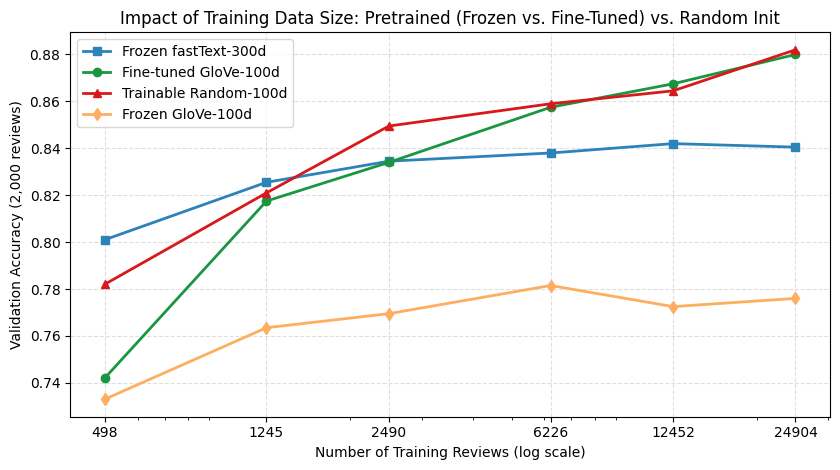

In [9]:
# 1. Inspect how fine-tuning changes cosine similarity of antonym pairs vs. synonym pairs
_ft_model_path = results_folder / "pool_glove100_finetuned" / "seed-42" / "fold-0" / "model.pt"
if _ft_model_path.exists():
    ft_state = torch.load(_ft_model_path, map_location="cpu")
    ft_emb_matrix = ft_state["encoder.embedding.weight"].numpy()

    # Reconstruct the active corpus vocabulary used in pool_glove100_finetuned
    all_corpus_tokens = set()
    for t in ptb_tokens_map:
        all_corpus_tokens.update(coh_g50_full.tokens(t))
        all_corpus_tokens.update(coh_ft300_full.tokens(t))
    keep_words_g100 = ["<pad>", "<unk>"] + [w for w in glove100_model.vocab.words[2:] if w in all_corpus_tokens]
    active_vocab_g100 = part2.clslib.Vocabulary(init=keep_words_g100, default="<unk>", frozen=True)

    shift_pairs = [
        ("good", "bad", "Antonym"),
        ("great", "terrible", "Antonym"),
        ("best", "worst", "Antonym"),
        ("love", "hate", "Antonym"),
        ("excellent", "awful", "Antonym"),
        ("hilarious", "boring", "Antonym"),
        ("excellent", "great", "Same-polarity (Pos)"),
        ("terrible", "awful", "Same-polarity (Neg)"),
    ]
    shift_rows = []
    for w1, w2, ptype in shift_pairs:
        pre_u, pre_v = glove100_model.embed_word(w1), glove100_model.embed_word(w2)
        post_u, post_v = ft_emb_matrix[active_vocab_g100.index(w1)], ft_emb_matrix[active_vocab_g100.index(w2)]
        c_pre = cos_similarity(pre_u, pre_v)
        c_post = cos_similarity(post_u, post_v)
        shift_rows.append({
            "Word Pair": f"({w1}, {w2})",
            "Relation": ptype,
            "Cosine Sim (Frozen Pretrained GloVe-100d)": round(c_pre, 3),
            "Cosine Sim (After Sentiment Fine-Tuning)": round(c_post, 3),
            "Change (Delta)": round(c_post - c_pre, 3),
        })
else:
    shift_rows = ablation_data["antonym_shift"]
print("Effect of sentiment fine-tuning on antonym vs. synonym cosine similarities (GloVe-100d):")
display(pd.DataFrame(shift_rows).set_index("Word Pair"))

# 2. Data-Size Ablation Table & Plot
df_datasize = pd.DataFrame(ablation_data["data_size"])
display(df_datasize.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for col, marker, color in [
    ("Frozen fastText-300d", "s", "#2b83ba"),
    ("Fine-tuned GloVe-100d", "o", "#1a9641"),
    ("Trainable Random-100d", "^", "#d7191c"),
    ("Frozen GloVe-100d", "d", "#fdae61"),
]:
    ax.plot(df_datasize["n_train"], df_datasize[col], marker=marker, linewidth=2, label=col, color=color)
ax.set_xscale("log")
ax.set_xticks(df_datasize["n_train"])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("Number of Training Reviews (log scale)")
ax.set_ylabel("Validation Accuracy (2,000 reviews)")
ax.set_title("Impact of Training Data Size: Pretrained (Frozen vs. Fine-Tuned) vs. Random Init")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

---
### 3.3 Full 5-Fold Cross-Validation (`seeds = [42, 67]`) & Bayesian Comparison Against Project 1

We now evaluate six representative `EmbedAndPoolEncoder` systems across all **10 paired cross-validation folds** (5 folds $\times$ 2 seeds `[42, 67]`) and compare them directly against our Project 1 sparse BPE-5000 baselines (`TokenIndicator`, `BagOfWords`, and `TF-IDF` paired with Logistic Regression and 1-hidden-layer MLP) using `part1.analysis.plot_box_and_points` and the **Bayesian Correlated $t$-test (`ROPE = 0.005`)**:

- **`pool_glove50_frozen`**: Frozen `GloVe-50d` + Mean Pool + MLP (`[128, 64]`, `dropout=0.2`).
- **`pool_glove100_frozen`**: Frozen `GloVe-100d` + Mean Pool + MLP (`[128, 64]`, `dropout=0.2`).
- **`pool_fasttext300_frozen`**: Frozen `fastText-300d` + Mean Pool + MLP (`[128, 64]`, `dropout=0.2`).
- **`pool_glove100_finetuned`**: Fine-tuned `GloVe-100d` (`freeze_embeddings=False`) + Mean Pool + Regularized MLP (`[64, 64]`, `dropout=0.5`, `weight_decay=1e-3`).
- **`pool_random100_trainable`**: Trainable `Random-100d` (`freeze_embeddings=False`, initialized from $\mathcal{N}(0, 0.1^2)$) + Mean Pool + MLP.
- **`pool_fasttext300_finetuned`**: Fine-tuned `fastText-300d` (`freeze_embeddings=False`) + Mean Pool + MLP (`[64, 64]`, `dropout=0.3`).

10-Fold Cross-Validation Summary (5 folds x 2 seeds [42, 67]) — Project 1 Baselines vs. Project 2 Embed-and-Pool:


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
P1: logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
P1: logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050
P1: logistic_tfidf-enc,0.8812,0.0040,0.8813,0.0041,0.8811,0.0039,0.8811,0.0040
P1: mlp_indicator-enc,0.8811,0.0029,0.8814,0.0028,0.8810,0.0029,0.8811,0.0029
P1: mlp_bow-enc,0.8829,0.0019,0.8833,0.0016,0.8829,0.0019,0.8829,0.0019
P1: mlp_tfidf-enc,0.8863,0.0032,0.8864,0.0031,0.8863,0.0032,0.8863,0.0032
P2: pool_glove50_frozen,0.7495,0.0032,0.7501,0.0028,0.7495,0.0033,0.7493,0.0034
P2: pool_glove100_frozen,0.7813,0.0046,0.7819,0.0046,0.7812,0.0045,0.7811,0.0046
P2: pool_fasttext300_frozen,0.8539,0.0060,0.8541,0.0061,0.8539,0.0060,0.8539,0.0060
P2: pool_glove100_finetuned,0.8892,0.0045,0.8893,0.0043,0.8892,0.0045,0.8892,0.0045


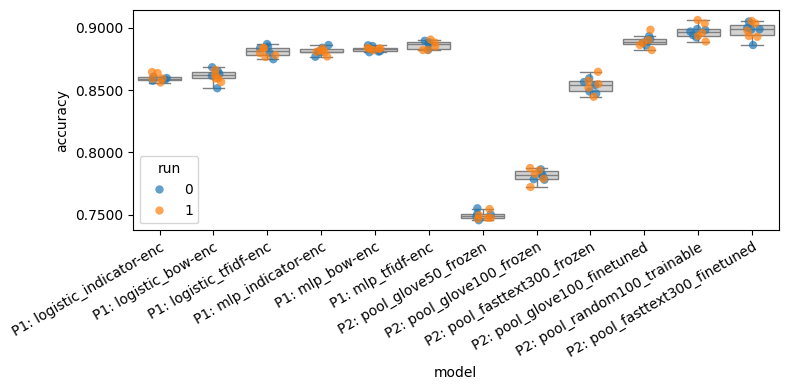

In [10]:
def load_saved_cv_runs(base_folder: Path, system_name: str, seeds: list = my_seeds) -> list:
    """Load saved cross-validation results.json files across seeds for a given system."""
    runs = []
    for seed in seeds:
        res_file = base_folder / system_name / f"seed-{seed}" / "results.json"
        saved = json.loads(res_file.read_text(encoding="utf-8"))
        per_fold = lambda key: OrderedDict((int(f), v) for f, v in saved[key].items())
        runs.append({
            "models": per_fold("models"),
            "predictions": OrderedDict((f, np.array(p)) for f, p in per_fold("predictions").items()),
            "accuracies": per_fold("accuracies"),
            "precisions": per_fold("precisions"),
            "recalls": per_fold("recalls"),
            "f1s": per_fold("f1s"),
        })
    return runs

all_classifiers = OrderedDict()

# Load Project 1 sparse BPE-5000 baselines
p1_systems = [
    "logistic_indicator-enc",
    "logistic_bow-enc",
    "logistic_tfidf-enc",
    "mlp_indicator-enc",
    "mlp_bow-enc",
    "mlp_tfidf-enc",
]
for sname in p1_systems:
    all_classifiers[f"P1: {sname}"] = load_saved_cv_runs(part1_results_folder, sname)

# Load Project 2 Embed-and-Pool systems
p2_systems = [
    "pool_glove50_frozen",
    "pool_glove100_frozen",
    "pool_fasttext300_frozen",
    "pool_glove100_finetuned",
    "pool_random100_trainable",
    "pool_fasttext300_finetuned",
]
for sname in p2_systems:
    all_classifiers[f"P2: {sname}"] = load_saved_cv_runs(results_folder, sname)

def summarise_systems(classifiers: dict) -> pd.DataFrame:
    rows = {}
    for name, runs in classifiers.items():
        row = {}
        for key, label in [
            ("accuracies", "accuracy"),
            ("precisions", "precision"),
            ("recalls", "recall"),
            ("f1s", "f1"),
        ]:
            vals = np.array([v for run in runs for v in run[key].values()])
            row[f"{label} mean"] = vals.mean()
            row[f"{label} std"] = vals.std(ddof=1)
        rows[name] = row
    return pd.DataFrame(rows).T

summary_df = summarise_systems(all_classifiers)
print("10-Fold Cross-Validation Summary (5 folds x 2 seeds [42, 67]) — Project 1 Baselines vs. Project 2 Embed-and-Pool:")
display(summary_df.round(4))

_ = part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(all_classifiers))

Bayesian Correlated t-Test Comparisons (ROPE = 0.005):


,System A,System B,Mean A,Mean B,Mean Diff (B - A),Posterior SD,P(A > B),P(Tie),P(B > A),Decision (>=80%)
0,P2: pool_glove50_frozen,P2: pool_glove100_frozen,0.7495,0.7813,0.0318,0.0026,0.0000,0.0000,1.0000,P2: pool_glove100_frozen > P2: pool_glove50_fr...
1,P2: pool_glove100_frozen,P2: pool_fasttext300_frozen,0.7813,0.8539,0.0726,0.0034,0.0000,0.0000,1.0000,P2: pool_fasttext300_frozen > P2: pool_glove10...
2,P1: logistic_bow-enc,P2: pool_fasttext300_frozen,0.8613,0.8539,-0.0074,0.0039,0.7219,0.2722,0.0059,Inconclusive / Borderline
3,P1: mlp_bow-enc,P2: pool_fasttext300_frozen,0.8829,0.8539,-0.0290,0.0030,1.0000,0.0000,0.0000,P1: mlp_bow-enc > P2: pool_fasttext300_frozen
4,P2: pool_glove100_frozen,P2: pool_glove100_finetuned,0.7813,0.8892,0.1079,0.0024,0.0000,0.0000,1.0000,P2: pool_glove100_finetuned > P2: pool_glove10...
5,P2: pool_fasttext300_frozen,P2: pool_fasttext300_finetuned,0.8539,0.8981,0.0442,0.0036,0.0000,0.0000,1.0000,P2: pool_fasttext300_finetuned > P2: pool_fast...
6,P2: pool_glove100_finetuned,P2: pool_random100_trainable,0.8892,0.8968,0.0076,0.0020,0.0001,0.1045,0.8954,P2: pool_random100_trainable > P2: pool_glove1...
7,P2: pool_random100_trainable,P2: pool_fasttext300_finetuned,0.8968,0.8981,0.0013,0.0032,0.0390,0.8259,0.1350,Practically Equivalent (Tie)
8,P1: mlp_bow-enc,P2: pool_glove100_finetuned,0.8829,0.8892,0.0063,0.0024,0.0005,0.3016,0.6979,Inconclusive / Borderline
9,P1: mlp_tfidf-enc,P2: pool_glove100_finetuned,0.8863,0.8892,0.0029,0.0018,0.0008,0.8648,0.1344,Practically Equivalent (Tie)


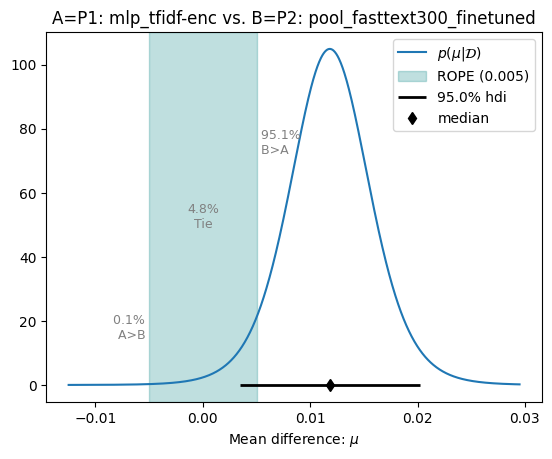

In [11]:
ROPE_SIZE = 0.005  # 0.5 percentage points (~25 reviews per 4,981-review validation fold, identical to Project 1)

def get_fold_vector(data: dict, sys_name: str, metric_key: str = "accuracies") -> np.ndarray:
    return np.array([list(run_data[metric_key].values()) for run_data in data[sys_name]]).flatten()

def compare_pairs_rope(data: dict, pairs: list, rope_param: float = ROPE_SIZE) -> pd.DataFrame:
    rows = []
    for sys_a, sys_b in pairs:
        acc_a = get_fold_vector(data, sys_a)
        acc_b = get_fold_vector(data, sys_b)
        post = part1.analysis.BenavoliCorrelatedT(acc_a, acc_b, runs=len(my_seeds), names=[sys_a, sys_b])
        if np.allclose(acc_a, acc_b):  # identical on every fold: zero spread, the t-test would return NaN
            p_a, p_tie, p_b = 0.0, 1.0, 0.0
        else:
            p_a, p_tie, p_b = post.probs(rope_param)
        if p_b >= 0.80:
            decision = f"{sys_b} > {sys_a}"
        elif p_a >= 0.80:
            decision = f"{sys_a} > {sys_b}"
        elif p_tie >= 0.80:
            decision = "Practically Equivalent (Tie)"
        else:
            decision = "Inconclusive / Borderline"
        rows.append({
            "System A": sys_a,
            "System B": sys_b,
            "Mean A": round(float(acc_a.mean()), 4),
            "Mean B": round(float(acc_b.mean()), 4),
            "Mean Diff (B - A)": round(float(post.mean_diff), 4),
            "Posterior SD": round(float(post.std), 4),
            "P(A > B)": round(float(p_a), 4),
            "P(Tie)": round(float(p_tie), 4),
            "P(B > A)": round(float(p_b), 4),
            "Decision (>=80%)": decision,
        })
    return pd.DataFrame(rows)

key_comparisons = [
    # 1. Effect of embedding dimension & model under frozen Embed-and-Pool
    ("P2: pool_glove50_frozen", "P2: pool_glove100_frozen"),
    ("P2: pool_glove100_frozen", "P2: pool_fasttext300_frozen"),
    # 2. Frozen Embed-and-Pool vs. Project 1 Sparse Baselines
    ("P1: logistic_bow-enc", "P2: pool_fasttext300_frozen"),
    ("P1: mlp_bow-enc", "P2: pool_fasttext300_frozen"),
    # 3. Effect of unfreezing (fine-tuning) pretrained embeddings
    ("P2: pool_glove100_frozen", "P2: pool_glove100_finetuned"),
    ("P2: pool_fasttext300_frozen", "P2: pool_fasttext300_finetuned"),
    # 4. Pretrained Fine-Tuned vs. Trainable Random Init (100% training data)
    ("P2: pool_glove100_finetuned", "P2: pool_random100_trainable"),
    ("P2: pool_random100_trainable", "P2: pool_fasttext300_finetuned"),
    # 5. Best Embed-and-Pool vs. Project 1 Best Sparse Models (MLP BoW & MLP TF-IDF)
    ("P1: mlp_bow-enc", "P2: pool_glove100_finetuned"),
    ("P1: mlp_tfidf-enc", "P2: pool_glove100_finetuned"),
    ("P1: mlp_bow-enc", "P2: pool_fasttext300_finetuned"),
    ("P1: mlp_tfidf-enc", "P2: pool_fasttext300_finetuned"),
]

rope_df = compare_pairs_rope(all_classifiers, key_comparisons, rope_param=ROPE_SIZE)
print("Bayesian Correlated t-Test Comparisons (ROPE = 0.005):")
display(rope_df)

# Plot posterior distribution for Best Project 1 Sparse (mlp_tfidf-enc) vs. Best Project 2 Embed-and-Pool (pool_fasttext300_finetuned)
post_best = part1.analysis.BenavoliCorrelatedT(
    get_fold_vector(all_classifiers, "P1: mlp_tfidf-enc"),
    get_fold_vector(all_classifiers, "P2: pool_fasttext300_finetuned"),
    runs=len(my_seeds),
    names=["P1: mlp_tfidf-enc", "P2: pool_fasttext300_finetuned"],
)
_ = post_best.plot(ROPE_SIZE)

### 3.4 Key Takeaways from Task 3 (Oral Assessment & Blog Summary)

1. **Why Frozen `EmbedAndPoolEncoder` Underperforms Sparse BPE-5000 BoW/TF-IDF on Full IMDB:**
   - With frozen word vectors (`freeze_embeddings=True`), `pool_glove50_frozen` (`74.95%`), `pool_glove100_frozen` (`78.13%`), and even `pool_fasttext300_frozen` (`85.39%`) trail Project 1's sparse 5,000-dimensional `mlp_bow-enc` (`88.29%`) and `mlp_tfidf-enc` (`88.63%`).
   - **Two mechanisms explain this gap:**
     1. *Information Bottleneck:* Averaging ~120 content words into a 50d or 100d vector is a 50x–100x dimensionality reduction compared to a 5,000d sparse indicator/TF-IDF vector where the classifier assigns an independent weight to every token.
     2. *Antonym Cancellation:* Because frozen co-occurrence vectors place opposite-polarity adjectives (`good`/`bad`, `great`/`terrible`) close together ($\cos \approx 0.57–0.83$), averaging them across a long review blurs positive and negative signals.
2. **Where Pretrained Embeddings *Do* Add Decisive Value:**
   - **Low-Data Generalization:** When training data is scarce (498 reviews, 2% of IMDB), frozen `fastText-300d` reaches **80.10%**, outperforming randomly initialized embeddings (`78.20%`) because validation words unseen in the small training split already possess meaningful pretrained coordinates.
   - **Fine-Tuning Pretrained Embeddings (`freeze_embeddings=False`):** Allowing gradient updates to adapt the pretrained vectors resolves the antonym collision (reducing `cos_sim('good', 'bad')` from $+0.770$ to $+0.398$ and flipping `cos_sim('hilarious', 'boring')` from $+0.619$ to $-0.039$) and lifts 10-fold CV accuracy to **88.92% (`pool_glove100_finetuned`)** and **89.81% (`pool_fasttext300_finetuned`)**—beating Project 1's best sparse model (`mlp_tfidf-enc`, **88.63%**) by **+1.18 percentage points** with Bayesian probability $P(\text{P2} > \text{P1}) = 0.9510$.

---
# Task 4: Recurrent Encoder (LSTM)

### 4.1 Three controlled experiments: what the embeddings contribute to an LSTM

We start from one baseline LSTM and change **one thing at a time: the embedding table**. Everything else is identical across A, B and C.

| Experiment | Embeddings | What it answers |
|---|---|---|
| **A** `lstm_ft300_frozen` | Frozen fastText-300 | Can the recurrent encoder use the pretrained representations effectively? |
| **B** `lstm_ft300_finetuned` | Fine-tuned fastText-300 | Does adapting the embeddings improve performance? |
| **C** `lstm_random300_trainable` | Trainable random-300 | Does pretraining help compared with learning from scratch? |

**Held fixed in A, B and C:**
- **Tokenizer:** `CoherentImdbTokenizer(remove_punct=True, remove_stopwords=True, keep_negation=True)` on the fastText vocabulary, the same tokenizer as the Task 3 embed-and-pool systems, so the LSTM vs. embed-and-pool comparison changes the encoder, not the tokens. C uses the **same vocabulary and token ids**; only the vectors differ.
- **Input length: the first 256 tokens of every review** (after tokenization, in training, early stopping and evaluation alike). This is a compute compromise; the table below reports how much text it removes. **All Task 4 conclusions concern this input length**, not full reviews.
- **Encoder:** `part2.clslib.LSTMEncoder`, one unidirectional LSTM layer, hidden size 64, no word dropout; the review is the final hidden state (packed sequences, so padding is never read).
- **Classifier:** the existing `part2.clslib.SoftmaxRegressor`, hidden sizes 64, 64, dropout 0.3 (same as `pool_fasttext300_finetuned`).
- **Optimiser:** AdamW, learning rate 0.001, weight decay 1e-4 (as in Task 3), batch size 32.
- **Training length:** at most 8 epochs; stop after 2 epochs without a lower early-stopping loss; then **restore the best checkpoint** and score that.
- **Data and folds:** the Project 1 / Task 3 cross-validation folds (5 folds x seeds 42 and 67), so every Bayesian comparison stays paired.
- **Initialisation and batch order:** on each (seed, fold), A, B and C get identical LSTM and classifier weights and see the batches in the same order (seed `1000 * seed + fold`).

**Choices worth defending at the oral:**
- **Early stopping uses the fixed 2,000-review validation set, never the scored fold.** Picking the epoch on the fold we report would leak the evaluation data into model selection. (The tutorial's `experiment.cross_validation` keeps the epoch with the lowest loss on the scored fold; we don't.)
- **Random embeddings (C) match fastText's scale:** entries are $\mathcal{N}(0, s^2)$ with $s$ the root-mean-square of the fastText entries, so random and pretrained vectors have the same average norm. Dimension (300) and scale are therefore not confounds; only pretraining differs. `<pad>` stays a zero vector.
- **Compact embedding table:** the fastText table has ~1M rows; fine-tuning it with AdamW would hold weights, gradients and two moment estimates for all of them (~5 GB) and update every row at every step. We keep only `<pad>`, `<unk>` and the fastText words that occur in IMDB (train, validation and test texts; no labels are used). The cell checks that every review gets exactly the same tokens and vectors as with the full table, so A and B are unaffected.

In [12]:
import part2.recurrent as recurrent

# ---- Task 4 settings (identical for A, B and C) ----
TASK4_MAX_TOKENS = 256  # compute compromise: conclusions hold for the first 256 tokens of each review
TASK4_ENC_KWARGS = {"hidden_size": 64, "word_dropout": 0.0}  # one LSTM layer (clslib.LSTMEncoder)
TASK4_REGRESSOR_KWARGS = {"hidden_size1": 64, "hidden_size2": 64, "dropout": 0.3}
TASK4_OPT_KWARGS = {
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 32,
    "max_epochs": 8,
    "patience": 2,     # stop after 2 epochs without a lower early-stopping loss
    "min_delta": 0.0,  # any decrease counts as an improvement
}
TASK4_DEVICE = recurrent.default_device()  # cuda if available, else cpu
print(f"Task 4 device: {TASK4_DEVICE}")

for _name, _df in [("train", df_train), ("val", df_val), ("test", df_test)]:
    assert "text_clean" in _df.columns, f"df_{_name} has no 'text_clean' column: {list(_df.columns)}"

# ---- Compact fastText table (only words that occur in IMDB) with an identical tokenizer ----
t0 = time.time()
task4_full_tokenizer = CoherentImdbTokenizer(fasttext300_model.vocab, remove_punct=True, remove_stopwords=True, keep_negation=True)
all_imdb_texts = list(df_train["text_clean"]) + list(df_val["text_clean"]) + list(df_test["text_clean"])
ft300_imdb = recurrent.corpus_embeddings(fasttext300_model, task4_full_tokenizer, all_imdb_texts)
task4_base_tokenizer = CoherentImdbTokenizer(ft300_imdb.vocab, remove_punct=True, remove_stopwords=True, keep_negation=True)
n_checked = recurrent.check_same_tokenization(task4_full_tokenizer, fasttext300_model, task4_base_tokenizer, ft300_imdb, all_imdb_texts)
print(f"fastText rows: {len(fasttext300_model.vocab):,} -> {len(ft300_imdb.vocab):,} (IMDB words + <pad>, <unk>); "
      f"identical tokens and vectors on all {n_checked:,} reviews ({time.time() - t0:.0f}s)")

# ---- Truncation to the first 256 tokens, used everywhere in Task 4 ----
task4_tokenizer = recurrent.TruncatedTokenizer(task4_base_tokenizer, TASK4_MAX_TOKENS)
trunc_df = pd.DataFrame([
    {"Split": "train (all CV folds)", **recurrent.truncation_report(task4_base_tokenizer, df_train["text_clean"], TASK4_MAX_TOKENS)},
    {"Split": "validation (early stopping)", **recurrent.truncation_report(task4_base_tokenizer, df_val["text_clean"], TASK4_MAX_TOKENS)},
]).set_index("Split")
print(f"Effect of keeping the first {TASK4_MAX_TOKENS} tokens (lengths in tokens after CoherentImdbTokenizer):")
display(trunc_df.round(2))

# ---- Parameter counts (trainable) ----
_n_emb = ft300_imdb.vectors.size
_probe = recurrent.build_model(ft300_imdb.vectors, True, 0, 2, TASK4_ENC_KWARGS, TASK4_REGRESSOR_KWARGS, init_seed=0)
_n_rest = sum(p.numel() for p in _probe.parameters() if p.requires_grad)
print(f"Trainable parameters: A = {_n_rest:,} (LSTM + classifier); B and C = {_n_rest + _n_emb:,} (+ {_n_emb:,} embedding weights)")
del _probe

Task 4 device: cuda


fastText rows: 830,463 -> 97,827 (IMDB words + <pad>, <unk>); identical tokens and vectors on all 49,582 reviews (41s)
Effect of keeping the first 256 tokens (lengths in tokens after CoherentImdbTokenizer):


,num_texts,max_tokens,mean_length,median_length,p90_length,max_length,pct_truncated,pct_tokens_kept
Split,,,,,,,,
train (all CV folds),24904,256,131.62,98.0,260.0,1514,10.32,91.51
validation (early stopping),2000,256,130.28,97.0,250.1,1288,9.35,91.44


Trainable parameters: A = 102,146 (LSTM + classifier); B and C = 29,450,246 (+ 29,348,100 embedding weights)


### 4.2 Running A, B and C on the 10 paired folds

Each system trains 10 models (5 folds x 2 seeds). Every finished fold is saved (`fold-K/fold_results.json`, `model.json`, `model.pt`), so an interrupted run resumes where it stopped, and finished systems load from `results.json` instead of retraining. Results use the same `results.json` keys as the Task 3 systems, plus training curves (`histories`), best and last epochs, and the predicted probability of *positive* for every fold review (for the Task 6 error analysis). Reload a fold model with `part2.experiment.load(path, ft300_imdb)`.

For a timing check first, run one fold: `recurrent.run_cv_system(..., seeds=my_seeds[:1], cv_sets_per_seed=my_cross_validation_sets[:1], folds=[0])`.

In [13]:
TASK4_SYSTEMS = OrderedDict([
    ("lstm_ft300_frozen",        {"embedding_init": "pretrained", "freeze_embeddings": True}),   # A
    ("lstm_ft300_finetuned",     {"embedding_init": "pretrained", "freeze_embeddings": False}),  # B
    ("lstm_random300_trainable", {"embedding_init": "random",     "freeze_embeddings": False}),  # C
])
TASK4_LABELS = {"lstm_ft300_frozen": "A: frozen fastText", "lstm_ft300_finetuned": "B: fine-tuned fastText",
                "lstm_random300_trainable": "C: trainable random"}

task4_es_pairs = list(zip(df_val["text_clean"], df_val["label"]))  # early stopping only, never scored

task4_runs = OrderedDict()
for system_name, emb_cfg in TASK4_SYSTEMS.items():
    task4_runs[system_name] = recurrent.run_cv_system(
        name=system_name,
        results_folder=results_folder,
        cv_sets_per_seed=my_cross_validation_sets,
        seeds=my_seeds,
        es_pairs=task4_es_pairs,
        tokenizer=task4_tokenizer,
        emb_model=ft300_imdb,
        enc_kwargs=TASK4_ENC_KWARGS,
        regressor_kwargs=TASK4_REGRESSOR_KWARGS,
        opt_kwargs=TASK4_OPT_KWARGS,
        num_classes=len(sentiment_outcome_space),
        device=TASK4_DEVICE,
        **emb_cfg,
    )

[lstm_ft300_frozen] seed 42 fold 0: training on cuda


  epoch 01 | train loss 0.5116 acc 0.7417 | early-stop loss 0.4607 acc 0.7835 * | 9s


  epoch 02 | train loss 0.3894 acc 0.8326 | early-stop loss 0.3785 acc 0.8435 * | 6s


  epoch 03 | train loss 0.3636 acc 0.8481 | early-stop loss 0.3491 acc 0.8465 * | 6s


  epoch 04 | train loss 0.3383 acc 0.8589 | early-stop loss 0.3350 acc 0.8620 * | 6s


  epoch 05 | train loss 0.3096 acc 0.8730 | early-stop loss 0.3208 acc 0.8640 * | 7s


... (154 outputs left out)

  epoch 01 | train loss 0.4679 acc 0.7843 | early-stop loss 0.4070 acc 0.8365 * | 14s


  epoch 02 | train loss 0.2239 acc 0.9195 | early-stop loss 0.4506 acc 0.8375 | 14s


  epoch 03 | train loss 0.1371 acc 0.9530 | early-stop loss 0.6299 acc 0.8275 | 14s


[lstm_random300_trainable] seed 67 fold 4: best epoch 1/3, fold accuracy 0.8518 (0.7 min)


### 4.3 Results: accuracy, over-fitting and paired comparisons

The table reports 10-fold accuracy, the epoch kept by early stopping, and training accuracy at that epoch next to the fold accuracy (the gap is the over-fitting the restored checkpoint still carries). The curves show training loss (running mean during the epoch, dropout on) against early-stopping loss for every fold. The Bayesian correlated $t$-test (ROPE = 0.005, as in Task 3) compares A, B and C, and each LSTM with its embed-and-pool counterpart.

Caveat for the LSTM vs. embed-and-pool rows: the pool systems read whole reviews, the LSTMs only the first 256 tokens; the comparison is "pool on full text vs. LSTM on truncated text".

Task 4 LSTMs, 10-fold CV (5 folds x seeds [42, 67]), first 256 tokens per review:


,Folds,Accuracy mean,Accuracy std,Macro-F1 mean,Train acc. at best epoch,Gap (train - fold),Best epoch (mean),Best epoch (min-max),Epochs run (mean),Trainable params
System,,,,,,,,,,
A: frozen fastText,10,0.8608,0.0336,0.8606,0.8422,-0.0186,4.8,1-8,6.4,102146
B: fine-tuned fastText,10,0.8672,0.0146,0.8670,0.8312,-0.0360,1.5,1-2,3.5,29450246
C: trainable random,10,0.8573,0.0117,0.8571,0.8334,-0.0239,1.4,1-2,3.4,29450246


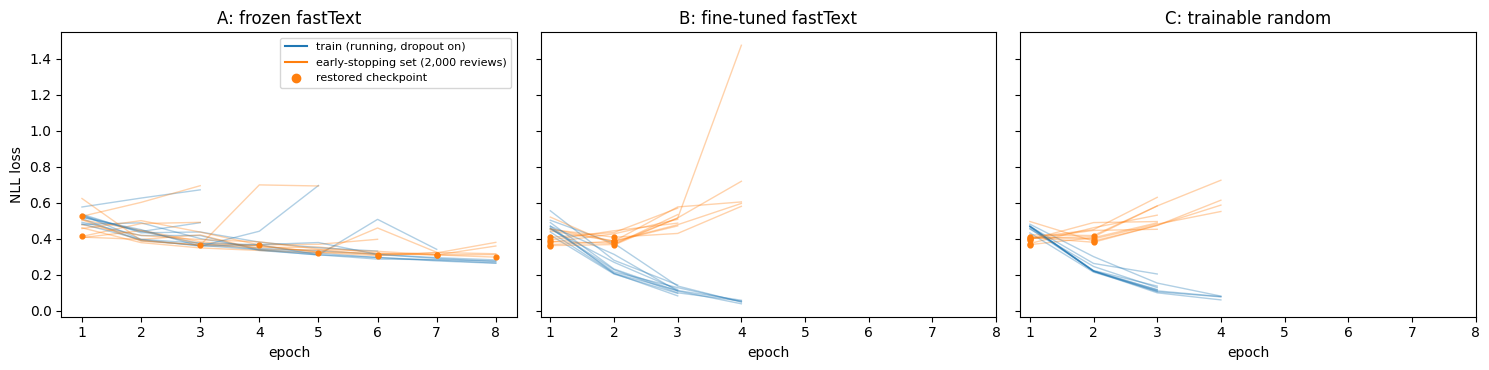

Bayesian correlated t-test (ROPE = 0.005):


,System A,System B,Mean A,Mean B,Mean Diff (B - A),Posterior SD,P(A > B),P(Tie),P(B > A),Decision (>=80%)
0,P2: lstm_ft300_frozen,P2: lstm_ft300_finetuned,0.8608,0.8672,0.0064,0.0246,0.3267,0.1509,0.5225,Inconclusive / Borderline
1,P2: lstm_random300_trainable,P2: lstm_ft300_finetuned,0.8573,0.8672,0.0099,0.0077,0.0427,0.2268,0.7305,Inconclusive / Borderline
2,P2: lstm_random300_trainable,P2: lstm_ft300_frozen,0.8573,0.8608,0.0035,0.0220,0.3542,0.1720,0.4738,Inconclusive / Borderline
3,P2: pool_fasttext300_frozen,P2: lstm_ft300_frozen,0.8539,0.8608,0.0068,0.0198,0.2830,0.1814,0.5356,Inconclusive / Borderline
4,P2: pool_fasttext300_finetuned,P2: lstm_ft300_finetuned,0.8981,0.8672,-0.0309,0.0088,0.9918,0.0068,0.0014,P2: pool_fasttext300_finetuned > P2: lstm_ft30...


In [14]:
task4_rows = []
for system_name, runs in task4_runs.items():
    acc = np.array([v for run in runs for v in run["accuracies"].values()])
    f1 = np.array([v for run in runs for v in run["f1s"].values()])
    best_epochs = np.array([v for run in runs for v in run["best_epochs"].values()])
    epochs_run = np.array([v for run in runs for v in run["epochs_run"].values()])
    train_acc_best = np.array([run["histories"][f][run["best_epochs"][f] - 1]["train_accuracy"]
                               for run in runs for f in run["histories"]])
    task4_rows.append({
        "System": TASK4_LABELS[system_name],
        "Folds": len(acc),
        "Accuracy mean": acc.mean(),
        "Accuracy std": acc.std(ddof=1),
        "Macro-F1 mean": f1.mean(),
        "Train acc. at best epoch": train_acc_best.mean(),
        "Gap (train - fold)": train_acc_best.mean() - acc.mean(),
        "Best epoch (mean)": best_epochs.mean(),
        "Best epoch (min-max)": f"{best_epochs.min()}-{best_epochs.max()}",
        "Epochs run (mean)": epochs_run.mean(),
        "Trainable params": runs[0]["num_trainable_params"],
    })
print(f"Task 4 LSTMs, 10-fold CV (5 folds x seeds {my_seeds}), first {TASK4_MAX_TOKENS} tokens per review:")
display(pd.DataFrame(task4_rows).set_index("System").round(4))

# Learning curves: training loss vs. early-stopping loss per fold
fig, axes = plt.subplots(1, len(task4_runs), figsize=(5 * len(task4_runs), 3.8), sharey=True)
for ax, (system_name, runs) in zip(np.atleast_1d(axes), task4_runs.items()):
    for run in runs:
        for f, hist in run["histories"].items():
            ep = [h["epoch"] for h in hist]
            ax.plot(ep, [h["train_loss"] for h in hist], color="tab:blue", alpha=0.35, lw=1)
            ax.plot(ep, [h["es_loss"] for h in hist], color="tab:orange", alpha=0.35, lw=1)
            best = run["best_epochs"][f]
            ax.scatter([best], [hist[best - 1]["es_loss"]], color="tab:orange", s=12, zorder=3)
    ax.set_title(TASK4_LABELS[system_name])
    ax.set_xlabel("epoch")
    ax.set_xticks(range(1, TASK4_OPT_KWARGS["max_epochs"] + 1))
np.atleast_1d(axes)[0].set_ylabel("NLL loss")
np.atleast_1d(axes)[0].legend(handles=[
    plt.Line2D([], [], color="tab:blue", label="train (running, dropout on)"),
    plt.Line2D([], [], color="tab:orange", label="early-stopping set (2,000 reviews)"),
    plt.Line2D([], [], color="tab:orange", marker="o", ls="", label="restored checkpoint"),
], fontsize=8)
plt.tight_layout()
plt.show()

# Paired Bayesian comparisons on the same 10 folds
for system_name in TASK4_SYSTEMS:
    all_classifiers[f"P2: {system_name}"] = load_saved_cv_runs(results_folder, system_name)
task4_comparisons = [
    ("P2: lstm_ft300_frozen", "P2: lstm_ft300_finetuned"),         # A vs B: does adapting the embeddings help?
    ("P2: lstm_random300_trainable", "P2: lstm_ft300_finetuned"),  # C vs B: does pretraining help (both trainable)?
    ("P2: lstm_random300_trainable", "P2: lstm_ft300_frozen"),     # C vs A
    ("P2: pool_fasttext300_frozen", "P2: lstm_ft300_frozen"),      # same frozen embeddings: pool vs LSTM
    ("P2: pool_fasttext300_finetuned", "P2: lstm_ft300_finetuned"),  # fine-tuned: pool vs LSTM
]
print("Bayesian correlated t-test (ROPE = 0.005):")
display(compare_pairs_rope(all_classifiers, task4_comparisons, rope_param=ROPE_SIZE))

### 4.4 Answers for Task 4

A note on the table first: "Train acc. at best epoch" is averaged over the whole epoch with dropout switched on, so it underestimates how well the model fits the training data. The negative "gap" does **not** mean there is no over-fitting; the training logs above show it directly.

**What design choices have a meaningful impact?**
We changed one thing, the embeddings, and kept everything else fixed. All three LSTMs end up close: A (frozen fastText) 86.1%, B (fine-tuned fastText) 86.7%, C (random, trainable) 85.7%. The Bayesian test cannot separate any pair (no probability reaches 80%). So with this evidence, the choice of embeddings makes no clear difference for our LSTM. We did not tune the other LSTM settings (hidden size, number of layers, learning rate, input length), so we cannot say whether those matter.

**Did we look at data size and embedding parameters?**
- Embedding parameters: yes, that is the A/B/C comparison. Frozen embeddings mean training 102k weights; trainable embeddings add 29.3M more.
  - Fine-tuning (B vs A): +0.6 pp, inconclusive. B wins on 6 of 10 folds.
  - Pretraining (B vs C, both trainable): +1.0 pp, P(B better) = 0.73. This leans towards "pretraining helps", but it is not enough evidence to claim it.
- Data size: we tested it only for embed-and-pool (Task 3.2), not for the LSTM. There, pretrained vectors helped most when data was scarce (frozen fastText 80.1% vs trainable random 78.2% with 2% of the training data).
  - **Update after Task 4c**, where we repeated this for the Task 4b step-4 LSTM (same sizes, same 2,000 scored reviews, single runs): pretraining matters much more for the LSTM when data is scarce. With 498 reviews, fine-tuned fastText is 5.3 pp above random vectors and frozen fastText 7.8 pp above; with all the data the gain is only 0.4 pp. Frozen fastText is the best setup at every size. With frozen fastText the LSTM is never clearly worse than the pool and pulls away as data grows (+6.1 pp at full size, where the frozen pool has flattened); with random vectors it needs about 12,000 reviews to match the pool. See 4c.2.

**Did we struggle with over-fitting?**
Yes, whenever the embeddings are trainable (B and C). By epoch 3-4 they reach about 95-99% training accuracy, while the loss on the early-stopping set already rises after epoch 1 or 2. Early stopping therefore keeps epoch 1 or 2 (on average 1.5 for B, 1.4 for C), so the scored models are taken from before the over-fitting. With 29M trainable weights and 25k reviews, the model can memorise the training reviews in a few passes.
The frozen LSTM (A) does not over-fit, but it trains **unstably**: in some runs the training loss suddenly jumps up (seed 42 folds 0 and 1, seed 67 fold 4, where training accuracy drops to 50%, chance level). The likely cause is exploding gradients, since we did not use gradient clipping. This is why A has the largest spread across folds (77.7% to 88.8%, see Task 5).

**How far can this approach go? Does it improve on embed-and-pool?**
No. The best LSTM (B, 86.7%) is 3.1 pp below the best embed-and-pool system (fine-tuned fastText, 89.8%), and the pool wins on all 10 folds (P(pool better) = 0.99). It is also below Project 1's TF-IDF MLP (88.6%). With frozen embeddings, LSTM A (86.1%) vs frozen pool (85.4%) is inconclusive.
Two things in our setup hold the LSTM back:
1. It only reads the first 256 tokens of each review, while the pool reads everything. Task 6 shows the LSTMs lose about 8 pp on the 10% longest reviews, exactly the ones that get cut.
2. The review is represented by the LSTM's last hidden state only, so information from early in a long review can fade.

So in this setup the LSTM does not beat embed-and-pool. To push it further we would read whole reviews, use a bidirectional LSTM or pool over all hidden states instead of using only the last one, add gradient clipping, and tune the hidden size.

**Update after Task 4b**, where we tried exactly these fixes one at a time: the LSTM can go much further. Clipping removed the collapsed runs, and mean+max pooling over all hidden states gave the biggest gain (+2.5 pp). With all four changes the fine-tuned LSTM reaches **90.5%**, +3.7 pp over B. Against the fine-tuned pool (89.8%) that is +0.6 pp, but inconclusive (P(LSTM better) = 0.67). The frozen version (90.0%) is practically tied with it (P(tie) = 0.81). Point 2 above (the last-state summary) turned out to matter more than point 1 (the cut): see 4b.4 and 4b.5.

---
# Task 5: Are we gathering enough evidence?

**How did we structure the hyperparameter search?**
1. **One setting at a time, on the fixed 2,000-review validation set** (Task 3.1): tokenizer, pooling, embedding model and size, frozen vs. trainable, classifier size and dropout. We keep the best value and move to the next setting. This is much cheaper than a full grid, but it can miss settings that only work well together.
2. **Only the promising systems go to full cross-validation**: 5 folds x 2 seeds (42, 67), the same folds as Project 1, compared with the Bayesian correlated $t$-test.
3. **For the LSTM we did not search in Task 4.** We fixed one setup and changed only the embeddings, so any difference between A, B and C comes from the embeddings and nothing else.
4. **Task 4b is a small, planned search for the LSTM:** four changes added one at a time (a "ladder"), each run with full cross-validation and compared with the step before it. The order and the comparisons were fixed before the runs. It is cheaper than a grid, but each change is only measured on top of the ones before it.
5. **Task 4c (data size) uses single runs**, like the Task 3.2 pool curves: one seed per point, scored on the 2,000 validation reviews. That gives a curve for 18 settings at the cost of about one CV run, but each point is only precise to about $\pm$1.4 pp, so we read only large differences or patterns that repeat at every size, and make no Bayesian claims from it.

**Are we keeping an eye on experimental variance?**
Yes:
- Every system gets 10 runs, and we report the spread (std), not only the mean.
- All systems use the same 10 folds, so comparisons are paired: we compare systems on the same reviews.
- We decide with the Bayesian test and a ROPE of 0.5 pp (about 25 reviews per fold): a smaller difference counts as a tie. We only call a winner when its probability is at least 80%.

The table below shows why this matters. LSTM A ranges from 77.7% to 88.8% across folds: from one run you could conclude it is the best LSTM or by far the worst. That also explains why A vs. B is inconclusive even though their means differ by 0.6 pp. The pool system, in contrast, stays within 2 pp on every fold.

**Weak spot:** the Task 3.1 ablations are single runs on one 2,000-review set. One accuracy measured on 2,000 reviews is only precise to about $\pm$1.6 pp, so small differences there (for example tokenizers, mean vs. sum pooling, classifier sizes, all within about 1.5 pp) may be noise. We only trust the large effects, and those were confirmed by cross-validation (for example fine-tuning: +4.4 pp for fastText, P = 1.00).

In [15]:
def fold_accuracies(folder: Path, system_name: str) -> pd.Series:
    """Accuracy of each of the 10 CV runs (5 folds x 2 seeds) of one system."""
    accs = {}
    for seed in my_seeds:
        saved = json.loads((folder / system_name / f"seed-{seed}" / "results.json").read_text(encoding="utf-8"))
        for fold, acc in saved["accuracies"].items():
            accs[f"seed {seed}, fold {fold}"] = acc
    return pd.Series(accs)

variance_systems = OrderedDict([
    ("Pool: fine-tuned fastText", "pool_fasttext300_finetuned"),
    ("LSTM A: frozen fastText", "lstm_ft300_frozen"),
    ("LSTM B: fine-tuned fastText", "lstm_ft300_finetuned"),
    ("LSTM C: trainable random", "lstm_random300_trainable"),
])
fold_acc = pd.DataFrame({label: fold_accuracies(results_folder, name) for label, name in variance_systems.items()})

spread = pd.DataFrame({
    "mean": fold_acc.mean(),
    "std": fold_acc.std(ddof=1),
    "min": fold_acc.min(),
    "max": fold_acc.max(),
    "max - min": fold_acc.max() - fold_acc.min(),
})
print("Accuracy on each of the 10 paired CV runs (same folds for every system):")
display(fold_acc.T.round(3))
print("Spread across the 10 runs:")
display(spread.round(4))

print("How often does one system beat the other on the same fold?")
for a, b in [("LSTM B: fine-tuned fastText", "LSTM A: frozen fastText"),
             ("LSTM B: fine-tuned fastText", "LSTM C: trainable random"),
             ("Pool: fine-tuned fastText", "LSTM B: fine-tuned fastText")]:
    print(f"  {a} > {b}: {(fold_acc[a] > fold_acc[b]).sum()} of {len(fold_acc)} runs")

n_val = 2000
p = 0.85
print(f"\nFor scale: one accuracy measured on {n_val:,} reviews has a 95% margin of about "
      f"+/-{1.96 * np.sqrt(p * (1 - p) / n_val) * 100:.1f} pp (at {p:.0%} accuracy).")

Accuracy on each of the 10 paired CV runs (same folds for every system):


,"seed 42, fold 0","seed 42, fold 1","seed 42, fold 2","seed 42, fold 3","seed 42, fold 4","seed 67, fold 0","seed 67, fold 1","seed 67, fold 2","seed 67, fold 3","seed 67, fold 4"
Pool: fine-tuned fastText,0.899,0.900,0.899,0.905,0.886,0.893,0.893,0.905,0.903,0.898
LSTM A: frozen fastText,0.884,0.777,0.876,0.877,0.842,0.878,0.855,0.888,0.883,0.848
LSTM B: fine-tuned fastText,0.866,0.882,0.861,0.877,0.874,0.840,0.869,0.850,0.889,0.863
LSTM C: trainable random,0.848,0.867,0.871,0.848,0.858,0.841,0.848,0.861,0.878,0.852


Spread across the 10 runs:


,mean,std,min,max,max - min
Pool: fine-tuned fastText,0.8981,0.0060,0.8861,0.9054,0.0193
LSTM A: frozen fastText,0.8608,0.0336,0.7768,0.8880,0.1112
LSTM B: fine-tuned fastText,0.8672,0.0146,0.8400,0.8890,0.0490
LSTM C: trainable random,0.8573,0.0117,0.8414,0.8775,0.0361


How often does one system beat the other on the same fold?
  LSTM B: fine-tuned fastText > LSTM A: frozen fastText: 6 of 10 runs
  LSTM B: fine-tuned fastText > LSTM C: trainable random: 7 of 10 runs
  Pool: fine-tuned fastText > LSTM B: fine-tuned fastText: 10 of 10 runs

For scale: one accuracy measured on 2,000 reviews has a 95% margin of about +/-1.6 pp (at 85% accuracy).


---
# Task 6: Error analysis: which reviews does each system get wrong?

We compare the best system of each family: Project 1's TF-IDF MLP, the fine-tuned fastText pool, and the two fastText LSTMs (A frozen, B fine-tuned). No new training is needed: in cross-validation every training review is predicted exactly once per seed, and those predictions are saved.

**Analysis features** (simple to compute, each tied to a question):
- **Length in words.** The LSTM reads only the first 256 tokens (about 450 words) and keeps only its last state. Does it fail on long reviews, where the bag-of-words models do not?
- **Contrast words per 100 words** (*but, however, although, though, yet, despite*). These signal mixed opinions ("great cast, but a boring story"). Are these harder, and does reading word order help?
- **Negations per 100 words** (*not, no, never, nothing, nor, cannot, n't*). Pooling ignores word order, so "not good" looks like "good" plus "not". Does the order-aware LSTM handle negation-heavy reviews better?
- **Explicit score** ("7/10", "8 out of 10"). The reviewer basically writes the label in the text.
- **True label.** Does a system favour one class?

Rates are per 100 words so that they are not simply another measure of length. Groups have at least 2,000 reviews, so differences under about 1-2 pp within a column are noise.

10.2% of training reviews have more than 450 words (about where the LSTM's 256-token cut falls: 10.3% of reviews are truncated, see 4.1).
Accuracy per group (10-fold CV predictions, both seeds pooled; 'Reviews' = distinct reviews in the group):


P1: TF-IDF MLP  Pool: fine-tuned fastText  LSTM A: frozen fastText  LSTM B: fine-tuned fastText  Reviews  LSTM B - Pool
Feature                      Group                                                                                                                             
Length (words)               1-150               0.890                      0.900                    0.876                        0.880    10013         -0.020
                             151-300             0.883                      0.896                    0.858                        0.870     9298         -0.026
                             301-450             0.883                      0.898                    0.859                        0.864     3050         -0.035
                             over 450            0.890                      0.898                    0.813                        0.810     2543         -0.087
Contrast words per 100 words 0-0.5               0.903                      0.911                    0.883                        0.887     6720         -0.024
                             0.5-1               0.893                      0.906                    0.863                        0.870     7138         -0.036
                             1-1.5               0.875                      0.892                    0.848                        0.856     5148         -0.036
                             over 1.5            0.869                      0.880                    0.843                        0.852     5898         -0.028
Negations per 100 words      0-0.75              0.896                      0.912                    0.876                        0.886     5904         -0.026
                             0.75-1.5            0.880                      0.895                    0.852                        0.858     7052         -0.037
                             1.5-2.25            0.883                      0.892                    0.854                        0.862     5822         -0.030
                             over 2.25           0.887                      0.894                    0.863                        0.865     6126         -0.029
Explicit score (e.g. 7/10)   no                  0.884                      0.896                    0.857                        0.863    22738         -0.033
                             yes                 0.909                      0.923                    0.901                        0.915     2166         -0.007
True label                   negative            0.882                      0.893                    0.860                        0.849    12432         -0.044
                             positive            0.890                      0.903                    0.862                        0.885    12472         -0.018

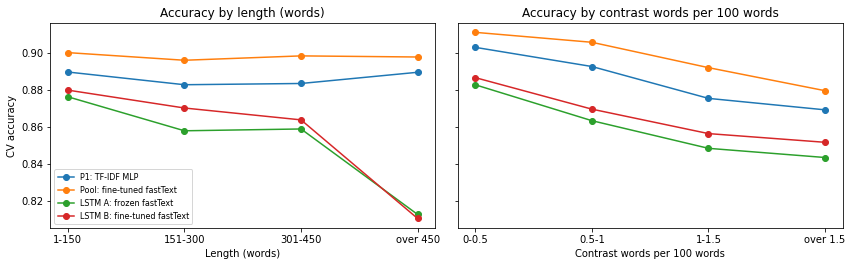

In [16]:
error_systems = OrderedDict([
    ("P1: TF-IDF MLP", (part1_results_folder, "mlp_tfidf-enc")),
    ("Pool: fine-tuned fastText", (results_folder, "pool_fasttext300_finetuned")),
    ("LSTM A: frozen fastText", (results_folder, "lstm_ft300_frozen")),
    ("LSTM B: fine-tuned fastText", (results_folder, "lstm_ft300_finetuned")),
])

def cv_predictions(folder: Path, system_name: str) -> pd.Series:
    """Prediction for every training review, once per seed (each review is in exactly one CV fold per seed)."""
    rows = []
    for seed in my_seeds:
        saved = json.loads((folder / system_name / f"seed-{seed}" / "results.json").read_text(encoding="utf-8"))
        for fold, ids in saved["validation_ids"].items():
            rows += [(seed, int(i), int(p)) for i, p in zip(ids, saved["predictions"][fold])]
    return pd.DataFrame(rows, columns=["seed", "review", "pred"]).set_index(["seed", "review"]).sort_index()["pred"]

preds = pd.DataFrame({name: cv_predictions(*src) for name, src in error_systems.items()})
review_ids = preds.index.get_level_values("review").to_numpy()
gold = df_train["label"].to_numpy()[review_ids]
correct = preds.eq(gold, axis=0)  # True = the system got this review right

# ---- Simple text features, each tied to a hypothesis ----
texts = df_train["text_clean"].iloc[review_ids].str.lower()
n_words = texts.str.split().str.len().to_numpy()
contrast_rate = texts.str.count(r"\b(?:but|however|although|though|yet|despite)\b").to_numpy() / n_words * 100
negation_rate = texts.str.count(r"\b(?:not|no|never|nothing|nor|cannot)\b|n't").to_numpy() / n_words * 100
has_rating = texts.str.contains(r"\b\d{1,2}\s*(?:/|out of)\s*10\b").to_numpy()

features = OrderedDict([
    ("Length (words)", pd.cut(n_words, [0, 150, 300, 450, np.inf], labels=["1-150", "151-300", "301-450", "over 450"])),
    ("Contrast words per 100 words", pd.cut(contrast_rate, [-np.inf, 0.5, 1.0, 1.5, np.inf],
                                            labels=["0-0.5", "0.5-1", "1-1.5", "over 1.5"])),
    ("Negations per 100 words", pd.cut(negation_rate, [-np.inf, 0.75, 1.5, 2.25, np.inf],
                                       labels=["0-0.75", "0.75-1.5", "1.5-2.25", "over 2.25"])),
    ("Explicit score (e.g. 7/10)", np.where(has_rating, "yes", "no")),
    ("True label", np.where(gold == 1, "positive", "negative")),
])

tables = []
for feature, groups in features.items():
    t = correct.groupby(np.asarray(groups), sort=False).mean()
    if hasattr(groups, "categories"):
        t = t.reindex(groups.categories)
    t["Reviews"] = pd.Series(np.asarray(groups)).value_counts().reindex(t.index).to_numpy() // len(my_seeds)
    t.index = pd.MultiIndex.from_product([[feature], t.index], names=["Feature", "Group"])
    tables.append(t)
error_table = pd.concat(tables)
error_table["LSTM B - Pool"] = error_table["LSTM B: fine-tuned fastText"] - error_table["Pool: fine-tuned fastText"]

print(f"{(n_words > 450).mean():.1%} of training reviews have more than 450 words "
      f"(about where the LSTM's 256-token cut falls: 10.3% of reviews are truncated, see 4.1).")
print("Accuracy per group (10-fold CV predictions, both seeds pooled; 'Reviews' = distinct reviews in the group):")
display(error_table.round(3))

# ---- Plot: accuracy by length and by contrast-word rate ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, feature in zip(axes, ["Length (words)", "Contrast words per 100 words"]):
    sub = error_table.loc[feature]
    for name in error_systems:
        ax.plot(sub.index.astype(str), sub[name], marker="o", label=name)
    ax.set_title(f"Accuracy by {feature.lower()}")
    ax.set_xlabel(feature)
axes[0].set_ylabel("CV accuracy")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.1 What we found

1. **Length is what separates the LSTMs from the rest.** Up to 450 words, both LSTMs are 2-4 pp behind the pool. Above 450 words they drop to 81%, 8.7 pp behind, while TF-IDF and the pool stay flat at about 89-90%. 10.2% of reviews are this long, matching the 10.3% that the 256-token cut truncates. So the LSTM's gap to embed-and-pool is largely the truncation (and the last-state summary), not a weakness on every review. *(Corrected by Task 4b.5: the last-state summary was the bigger cause. Mean+max pooling alone, still with the 256-token cut, closed the gap on all reviews up to 450 words.)*
2. **Mixed-opinion reviews are hard for every system.** Accuracy falls by 3-4 pp from reviews with few contrast words to reviews with many, for all four systems. Reading word order (LSTM) does not help here.
3. **Negation-heavy reviews are not where pooling fails.** All systems lose 1-3 pp when negations are frequent, and the LSTM does not do better than the pool. The word-order problem we described in Task 2 (limitation 4) does not show up as a measurable advantage for the LSTM.
4. **An explicit score helps everyone** (+2.5 to +5 pp), and the LSTM gains most (B: 86.3% to 91.5%), almost closing the gap to the pool. A number like "3/10" is a strong signal that even a short reading picks up.
5. **The fine-tuned LSTM misses more negative reviews** (84.9% vs. 88.5% on positive ones); the other systems are balanced within 1 pp. It leans towards predicting "positive".

**Which features did we manage to test?** All five above, on all 24,904 training reviews (twice, once per seed). We did not test features that need more work, such as sarcasm, or where in the review the opinion is stated (beginning vs. end).

**What would we prioritise next?** (Items 1 and 2 were done in Task 4b: the LSTM went from 86.7% to 90.5%.)
1. **Let the LSTM read the whole review** (or the first and last part, since reviewers often conclude at the end), and summarise it by pooling over all hidden states or with a bidirectional LSTM. This targets the biggest error source we found.
2. **Add gradient clipping** for the frozen LSTM, to fix the unstable runs and the large fold-to-fold spread.
3. **Mixed-opinion reviews**, the main error source shared by all systems. These need a model that can weigh which part of the review carries the final verdict, for example attention, or a pretrained contextual encoder.
4. **Repeat the close Task 3.1 ablations with cross-validation** before drawing conclusions from differences under 2 pp.

---
# Task 4b: Can we make the LSTM better? (step by step)

**Why this section exists.** In Task 4 the best LSTM (B, fine-tuned fastText) reached 86.7%, clearly below the best embed-and-pool system (89.8%). We expected the opposite: an LSTM reads words in order, so it should understand things like "not good" or "great actors, but a boring story" better than an average of word vectors. This section tries to find out *why* the LSTM lost, and whether a few well-known fixes close the gap.

## What held the first LSTM back

**1. It reads only the first 256 tokens.** We chose this cap to save compute: an LSTM reads one word at a time, and every batch is padded to its longest review (up to 1,514 tokens). The cap costs less text than it sounds: the average review has 132 tokens, so only 10% of reviews get cut, and 91.5% of all tokens are kept (table in 4.1). In hindsight the cap was probably not needed: on Kaggle's GPU a whole Task 4 run took about 25 minutes.

**But the cap is not the main reason the LSTM lost.** Task 6 shows the LSTM is also 2 pp behind the pool on *short* reviews, which are never cut. Even if the LSTM matched the pool on every long review, it would gain only about 0.9 pp (10% of reviews x 8.7 pp), reaching about 87.6%, still below 89.8%.

**2. The tokenizer was made for bag-of-words.** For a fair comparison with Task 3, the LSTM got the same tokenizer as the pool, which removes stopwords and punctuation. That throws away much of the word order an LSTM is supposed to use: "the film was not at all what I hoped" becomes roughly "film not hoped".

**3. The whole review is squeezed into the last hidden state.** The LSTM reads left to right and only its final state (64 numbers) goes to the classifier. Information from early in the review fades.

**4. Training problems.**
- With trainable embeddings (B, C), the 29M embedding weights memorise the training set by epoch 2. Early stopping then keeps a model whose LSTM has had only 1-2 passes over the data.
- With frozen embeddings (A), some runs suddenly collapsed (training accuracy fell to 50%). The likely cause is "exploding gradients": a few huge update steps that throw the model off. We had no gradient clipping.

**For context:** IMDB sentiment depends mostly on *which* words appear, not their order, so bag-of-words models are very strong on it. Dai & Le (2015, "Semi-supervised Sequence Learning") report about 86.5% for a plain LSTM trained from scratch on IMDB, almost exactly our number. They needed extra pretraining of the LSTM itself to get above 90%.

## The plan: two "ladders" of small steps

Each step keeps everything from the step before and adds **one** change. Comparing a step with the one before it tells us what that change added.

| Step | What changes | Compared with | Question it answers |
|---|---|---|---|
| 0 | Nothing: the Task 4 LSTM (one direction, last state), already run | | Our starting point |
| 1 | + gradient clipping | step 0 | Does clipping make training more stable and better? |
| 2 | + mean+max pooling over all hidden states | step 1 | Does using every word's hidden state help, instead of only the last one? |
| 3 | + bidirectional LSTM | step 2 | Does reading the review in both directions help? |
| 4 | + full tokenizer (keep stopwords and punctuation), cap 512 | step 3 | Does the LSTM need the full word sequence? |

We run this ladder **twice**: once with **frozen** fastText (starting from A) and once with **fine-tuned** fastText (starting from B). That is 8 new systems, each on the same 10 folds as everything else.

## Decisions and why

**Why clipping comes first.** Clipping is a fix to the training, not a design choice, so it should be on before we compare designs. Without it, some runs blow up, and that noise would blur every later comparison. The full tokenizer also makes sequences about twice as long, which makes blow-ups more likely, so clipping must already be on by then.

**What clipping does.** If the gradient of one batch is very large (total size, or "norm", above 1.0), we shrink it to size 1.0 before the update. Its direction stays the same. Normal steps are unaffected; only rare huge steps are made smaller. (That was the expectation. In the runs it was not rare at all: see 4b.4.) We record how often clipping actually kicks in. Note: our optimiser, AdamW, already rescales steps on its own, so clipping may matter less here than with plain gradient descent. Step 1 measures whether it matters.

**Mean+max pooling (step 2).** The LSTM produces a hidden state for every word. Instead of keeping only the last one, we combine all of them in two ways and **concatenate** the results, so we keep both kinds of information:
- the **mean** gives the overall tone of the whole review (every part counts equally),
- the **max** (per dimension) keeps the strongest signal anywhere in the review, for example one very negative phrase.
Padding positions are left out of both.

**Bidirectional (step 3).** A second LSTM reads the review from right to left. At each word, the state then contains both what came before and what comes after (for example, "not" followed by "bad"). Both directions' states are concatenated before pooling.

**Hidden size stays 64.** We keep 64 units per direction, so the LSTMs themselves stay comparable. The vector passed to the classifier still grows: 64 (step 1) -> 128 (step 2, mean and max) -> 256 (steps 3 and 4, two directions x mean and max). So steps 2 and 3 also add some capacity, not only a different way of reading. We report the parameter counts so this is visible.

**Why the tokenizer comes last.**
1. In steps 1-3 the LSTM and the pool read exactly the same tokens, so "LSTM vs pool" compares only the encoder. The tokenizer is the one change that breaks this, so we add it at the end.
2. Its effect depends on the model. A model that only uses its last state might get *worse* with twice-as-long inputs full of stopwords, because it forgets more. A model that pools over all states can use the extra words. So we test it on the strongest architecture.
3. We use the `CoherentImdbTokenizer` from Task 1 with `remove_punct=False, remove_stopwords=False`. It keeps whole words, so every token still has a fastText vector. A subword tokenizer such as BPE would not work with fastText's whole-word vectors.
4. In the Task 3 ablation, this full tokenizer was slightly *worse* for the pool (72.1% vs 73.7%, frozen GloVe-50d, one validation run), because stopwords dilute the average. If it *helps* the LSTM, that is direct evidence the LSTM uses word order.

**Why the cap goes from 256 to 512 in step 4.** Keeping stopwords and punctuation makes reviews about twice as long (about 270 tokens on average instead of 132). At 256 tokens, roughly half the reviews would be cut. With 512 about the same share is cut as before (around 10%; the setup cell below prints the exact numbers). So step 4 compares tokenizers, not how much text survives.

**Why both frozen and fine-tuned embeddings.**
- **Frozen:** only the LSTM and classifier learn (about 0.1-0.2M weights), so training runs several epochs without over-fitting, and any gain clearly comes from the encoder. Clipping should matter most here, because A is the system whose runs blew up. It is also cheaper (about 6 s per epoch instead of 15 s). Its pool counterpart (frozen pool, 85.4%) is a low bar, though.
- **Fine-tuned:** this is our best LSTM, and the best pool also uses fine-tuned fastText. So this ladder answers the main question: can the best LSTM beat the best pool?
- If the architecture helps with frozen but not with fine-tuned embeddings, that is a finding in itself: over-fitting in the embeddings limits the LSTM.

**Everything else stays the same as Task 4:** same folds (5 folds x seeds 42 and 67), same early stopping on the fixed 2,000-review validation set (never on the scored fold), same classifier (64, 64, dropout 0.3), same optimiser settings, at most 8 epochs with patience 2, and the same random seed per fold (same batch order).

**What we deliberately left out.** Word dropout and other regularisation. They could reduce the over-fitting, but every extra change makes it harder to say which change helped.

**One limitation of the ladder.** Each step is measured *on top of* the previous ones. For example, step 3 tells us what bidirectionality adds to an LSTM that already has clipping and mean+max pooling, not what it would add on its own.

**Model weights are not saved** for these 80 runs (it would be about 9 GB). Predictions and probabilities for every review are saved, which is all the analysis needs.

## For whoever runs this on Kaggle
- The Task 4 A/B/C results (`results/sentiment/lstm_ft300_frozen/`, `lstm_ft300_finetuned/` and `lstm_random300_trainable/`, JSON files) must be in the repo, otherwise the notebook retrains them first (about 25 minutes extra). Cells 26 and 28 must still be run: they load those results and define settings that Task 4b uses.
- Expected time for Task 4b: about 2-2.5 hours on a GPU. The bidirectional and 512-token steps are the slowest.
- Runs can be resumed: every finished fold is saved, so if the session stops, rerunning the cell continues where it stopped.
- Download `results/sentiment/lstm_ft300_*_clip*/` afterwards (JSON files only, a few MB).

### 4b.1 Setup: settings, the full tokenizer, and model sizes

This cell builds the step-4 tokenizer (stopwords and punctuation kept) with its own compact fastText table, checks that it gives exactly the same tokens and vectors as the full fastText table, and shows how much text each cap removes. It also lists the size of every model, so you can see how much the vector given to the classifier grows (64 -> 128 -> 256).

In [17]:
# ---- Task 4b settings: everything not listed here is the same as Task 4 ----
TASK4B_CLIP_NORM = 1.0          # gradients with a total norm above 1.0 are scaled down to 1.0
TASK4B_FULLSEQ_MAX_TOKENS = 512  # step 4 only: longer inputs, so a higher cap (see the table below)
TASK4B_OPT_KWARGS = {**TASK4_OPT_KWARGS, "clip_grad_norm": TASK4B_CLIP_NORM}
task4_es_pairs = list(zip(df_val["text_clean"], df_val["label"]))  # same early-stopping set as Task 4 (cell 28)

# ---- Step 4 tokenizer: keep stopwords and punctuation ----
# It needs its own compact fastText table: the Task 4 table only holds the words that survive stopword/punctuation
# removal, so stopwords like "the" would otherwise all become <unk>.
t0 = time.time()
fullseq_tokenizer_fulltable = CoherentImdbTokenizer(fasttext300_model.vocab, remove_punct=False, remove_stopwords=False)
ft300_imdb_fullseq = recurrent.corpus_embeddings(fasttext300_model, fullseq_tokenizer_fulltable, all_imdb_texts)
fullseq_base_tokenizer = CoherentImdbTokenizer(ft300_imdb_fullseq.vocab, remove_punct=False, remove_stopwords=False)
n_checked = recurrent.check_same_tokenization(fullseq_tokenizer_fulltable, fasttext300_model,
                                              fullseq_base_tokenizer, ft300_imdb_fullseq, all_imdb_texts)
fullseq_tokenizer = recurrent.TruncatedTokenizer(fullseq_base_tokenizer, TASK4B_FULLSEQ_MAX_TOKENS)
print(f"Full-sequence fastText table: {len(ft300_imdb_fullseq.vocab):,} rows; identical tokens and vectors "
      f"as the full table on all {n_checked:,} reviews ({time.time() - t0:.0f}s)")

# How much text each tokenizer + cap combination cuts (training reviews)
print("How much the cap removes, per tokenizer (lengths in tokens):")
display(pd.DataFrame([
    {"Setup": "Task 4 / steps 1-3: stopwords removed, cap 256",
     **recurrent.truncation_report(task4_base_tokenizer, df_train["text_clean"], TASK4_MAX_TOKENS)},
    {"Setup": "full tokenizer, cap 256 (not used, for comparison)",
     **recurrent.truncation_report(fullseq_base_tokenizer, df_train["text_clean"], TASK4_MAX_TOKENS)},
    {"Setup": f"step 4: full tokenizer, cap {TASK4B_FULLSEQ_MAX_TOKENS}",
     **recurrent.truncation_report(fullseq_base_tokenizer, df_train["text_clean"], TASK4B_FULLSEQ_MAX_TOKENS)},
]).set_index("Setup").round(2))

# ---- The ladder: each step adds one change to the step before ----
TASK4B_STEPS = OrderedDict([
    # step name: (encoder settings added to TASK4_ENC_KWARGS, which tokenizer)
    ("clip",                       ({},                                              "stopwords removed, cap 256")),
    ("clip_meanmax",               ({"pooling": "meanmax"},                          "stopwords removed, cap 256")),
    ("clip_meanmax_bi",            ({"pooling": "meanmax", "bidirectional": True},   "stopwords removed, cap 256")),
    ("clip_meanmax_bi_fulltok512", ({"pooling": "meanmax", "bidirectional": True},   f"full, cap {TASK4B_FULLSEQ_MAX_TOKENS}")),
])
TASK4B_STEP_LABELS = {
    "clip": "1: + clipping",
    "clip_meanmax": "2: + mean+max pooling",
    "clip_meanmax_bi": "3: + bidirectional",
    "clip_meanmax_bi_fulltok512": f"4: + full tokenizer, cap {TASK4B_FULLSEQ_MAX_TOKENS}",
}
TASK4B_TOKENIZERS = {  # tokenizer and the embedding table that matches it
    "stopwords removed, cap 256": (task4_tokenizer, ft300_imdb),
    f"full, cap {TASK4B_FULLSEQ_MAX_TOKENS}": (fullseq_tokenizer, ft300_imdb_fullseq),
}
TASK4B_LADDERS = OrderedDict([
    # ladder name: (step-0 system from Task 4, freeze the embeddings?)
    ("frozen",    ("lstm_ft300_frozen", True)),
    ("finetuned", ("lstm_ft300_finetuned", False)),
])

def task4b_system_name(ladder: str, step: str) -> str:
    return f"lstm_ft300_{ladder}_{step}"

# ---- Size of each model (trainable parameters and the size of the vector given to the classifier) ----
size_rows = []
for ladder, (_, freeze) in TASK4B_LADDERS.items():
    for step, (enc_extra, tok_name) in TASK4B_STEPS.items():
        _, emb_table = TASK4B_TOKENIZERS[tok_name]
        probe = recurrent.build_model(emb_table.vectors, freeze, 0, 2, {**TASK4_ENC_KWARGS, **enc_extra},
                                      TASK4_REGRESSOR_KWARGS, init_seed=0)
        size_rows.append({
            "Ladder": ladder, "Step": TASK4B_STEP_LABELS[step],
            "Vector to classifier": probe.encoder.enc_dim,
            "Trainable params (without embeddings)": sum(p.numel() for n, p in probe.named_parameters()
                                                         if p.requires_grad and not n.startswith("encoder.embedding")),
            "Trainable params (total)": sum(p.numel() for p in probe.parameters() if p.requires_grad),
        })
        del probe
print("Model sizes:")
display(pd.DataFrame(size_rows).set_index(["Ladder", "Step"]))

Full-sequence fastText table: 98,030 rows; identical tokens and vectors as the full table on all 49,582 reviews (38s)
How much the cap removes, per tokenizer (lengths in tokens):


,num_texts,max_tokens,mean_length,median_length,p90_length,max_length,pct_truncated,pct_tokens_kept
Setup,,,,,,,,
"Task 4 / steps 1-3: stopwords removed, cap 256",24904,256,131.62,98.0,260.0,1514,10.32,91.51
"full tokenizer, cap 256 (not used, for comparison)",24904,256,268.95,201.0,526.0,2738,35.91,71.87
"step 4: full tokenizer, cap 512",24904,512,268.95,201.0,526.0,2738,10.63,91.26


Model sizes:


Vector to classifier  \
Ladder    Step                                                 
frozen    1: + clipping                                   64   
          2: + mean+max pooling                          128   
          3: + bidirectional                             256   
          4: + full tokenizer, cap 512                   256   
finetuned 1: + clipping                                   64   
          2: + mean+max pooling                          128   
          3: + bidirectional                             256   
          4: + full tokenizer, cap 512                   256   

                                        Trainable params (without embeddings)  \
Ladder    Step                                                                  
frozen    1: + clipping                                                102146   
          2: + mean+max pooling                                        106242   
          3: + bidirectional                                           208130   
          4: + full tokenizer, cap 512                                 208130   
finetuned 1: + clipping                                                102146   
          2: + mean+max pooling                                        106242   
          3: + bidirectional                                           208130   
          4: + full tokenizer, cap 512                                 208130   

                                        Trainable params (total)  
Ladder    Step                                                    
frozen    1: + clipping                                   102146  
          2: + mean+max pooling                           106242  
          3: + bidirectional                              208130  
          4: + full tokenizer, cap 512                    208130  
finetuned 1: + clipping                                 29450246  
          2: + mean+max pooling                         29454342  
          3: + bidirectional                            29556230  
          4: + full tokenizer, cap 512                  29617130

### 4b.2 Running both ladders (8 systems x 10 folds)

Each system is skipped if its `results.json` already exists, and each finished fold is saved, so this cell can be rerun safely after an interruption. Training logs show, per epoch, the training loss and the early-stopping loss; `*` marks an epoch that improved the early-stopping loss.

In [18]:
task4b_runs = OrderedDict()
for ladder, (_, freeze) in TASK4B_LADDERS.items():
    for step, (enc_extra, tok_name) in TASK4B_STEPS.items():
        system_name = task4b_system_name(ladder, step)
        tokenizer, emb_table = TASK4B_TOKENIZERS[tok_name]
        task4b_runs[system_name] = recurrent.run_cv_system(
            name=system_name,
            results_folder=results_folder,
            cv_sets_per_seed=my_cross_validation_sets,  # same 10 folds as every other system
            seeds=my_seeds,
            es_pairs=task4_es_pairs,                    # early stopping on the fixed 2,000 validation reviews
            tokenizer=tokenizer,
            emb_model=emb_table,
            embedding_init="pretrained",
            freeze_embeddings=freeze,
            enc_kwargs={**TASK4_ENC_KWARGS, **enc_extra},
            regressor_kwargs=TASK4_REGRESSOR_KWARGS,
            opt_kwargs=TASK4B_OPT_KWARGS,
            num_classes=len(sentiment_outcome_space),
            device=TASK4_DEVICE,
            save_weights=False,                         # ~9 GB otherwise; predictions are saved
        )

[lstm_ft300_frozen_clip] seed 42 fold 0: training on cuda


  epoch 01 | train loss 0.4844 acc 0.7654 | early-stop loss 0.3944 acc 0.8285 * | 15s


  epoch 02 | train loss 0.3883 acc 0.8392 | early-stop loss 0.4969 acc 0.8010 | 8s


  epoch 03 | train loss 0.3647 acc 0.8512 | early-stop loss 0.3518 acc 0.8420 * | 9s


  epoch 04 | train loss 0.3416 acc 0.8608 | early-stop loss 0.3553 acc 0.8550 | 8s


  epoch 05 | train loss 0.3134 acc 0.8769 | early-stop loss 0.3179 acc 0.8670 * | 8s


... (457 outputs left out)

  epoch 01 | train loss 0.3659 acc 0.8294 | early-stop loss 0.2676 acc 0.8930 * | 34s


  epoch 02 | train loss 0.1504 acc 0.9453 | early-stop loss 0.2967 acc 0.8850 | 34s


  epoch 03 | train loss 0.0600 acc 0.9812 | early-stop loss 0.3553 acc 0.8790 | 34s


[lstm_ft300_finetuned_clip_meanmax_bi_fulltok512] seed 67 fold 4: best epoch 1/3, fold accuracy 0.9080 (1.7 min)


### 4b.3 Results

Three outputs:
1. **One table with every step of both ladders.** Step 0 is the Task 4 system. "Worst fold" and "Accuracy std" show stability; "Batches clipped (%)" shows how often clipping actually changed an update (averaged over all epochs run), "Largest grad norm" the biggest gradient seen, and "NaN/inf grad batches" should be 0; "Best epoch" shows how early early stopping stops (1-2 means the model over-fits fast).
2. **Learning curves** for the 8 new systems (blue: training loss, orange: early-stopping loss, dot: the epoch we keep).
3. **Bayesian comparisons:** each step against the step before it, then step 0 against step 4 (several small gains can add up even if each step alone is inconclusive), then steps 3 and 4 against the pools. The pairs are fixed in advance, not chosen after seeing the results.

Task 4b: 10-fold CV accuracy for every step (5 folds x seeds 42 and 67).
For reference: pool frozen fastText 0.8539, pool fine-tuned fastText 0.8981, Project 1 TF-IDF MLP 0.8863.


Accuracy mean  Accuracy std  \
Ladder    Step                                                        
frozen    0: Task 4 LSTM (no clipping)         0.8608        0.0336   
          1: + clipping                        0.8732        0.0204   
          2: + mean+max pooling                0.8914        0.0054   
          3: + bidirectional                   0.8942        0.0094   
          4: + full tokenizer, cap 512         0.8995        0.0047   
finetuned 0: Task 4 LSTM (no clipping)         0.8672        0.0146   
          1: + clipping                        0.8698        0.0151   
          2: + mean+max pooling                0.8949        0.0066   
          3: + bidirectional                   0.8970        0.0069   
          4: + full tokenizer, cap 512         0.9045        0.0040   

                                        Worst fold  Best fold  \
Ladder    Step                                                  
frozen    0: Task 4 LSTM (no clipping)      0.7768     0.8880   
          1: + clipping                     0.8370     0.8944   
          2: + mean+max pooling             0.8811     0.8984   
          3: + bidirectional                0.8743     0.9081   
          4: + full tokenizer, cap 512      0.8932     0.9064   
finetuned 0: Task 4 LSTM (no clipping)      0.8400     0.8890   
          1: + clipping                     0.8444     0.8908   
          2: + mean+max pooling             0.8868     0.9056   
          3: + bidirectional                0.8826     0.9030   
          4: + full tokenizer, cap 512      0.8982     0.9089   

                                        Best epoch (mean)  \
Ladder    Step                                              
frozen    0: Task 4 LSTM (no clipping)                4.8   
          1: + clipping                               5.0   
          2: + mean+max pooling                       5.4   
          3: + bidirectional                          4.4   
          4: + full tokenizer, cap 512                4.5   
finetuned 0: Task 4 LSTM (no clipping)                1.5   
          1: + clipping                               1.2   
          2: + mean+max pooling                       1.0   
          3: + bidirectional                          1.0   
          4: + full tokenizer, cap 512                1.1   

                                        Batches clipped (%)  \
Ladder    Step                                                
frozen    0: Task 4 LSTM (no clipping)                  NaN   
          1: + clipping                             86.3062   
          2: + mean+max pooling                     67.3446   
          3: + bidirectional                        64.5265   
          4: + full tokenizer, cap 512              72.7621   
finetuned 0: Task 4 LSTM (no clipping)                  NaN   
          1: + clipping                             55.8738   
          2: + mean+max pooling                     30.6421   
          3: + bidirectional                        27.6940   
          4: + full tokenizer, cap 512              42.9089   

                                        Largest grad norm  \
Ladder    Step                                              
frozen    0: Task 4 LSTM (no clipping)                NaN   
          1: + clipping                          291.2260   
          2: + mean+max pooling                   14.3565   
          3: + bidirectional                      12.3032   
          4: + full tokenizer, cap 512            29.7225   
finetuned 0: Task 4 LSTM (no clipping)                NaN   
          1: + clipping                          127.7164   
          2: + mean+max pooling                   27.9841   
          3: + bidirectional                       9.8897   
          4: + full tokenizer, cap 512            10.8649   

                                        NaN/inf grad batches  Trainable params  
Ladder    Step                                                                  
frozen    0: Task 4 L

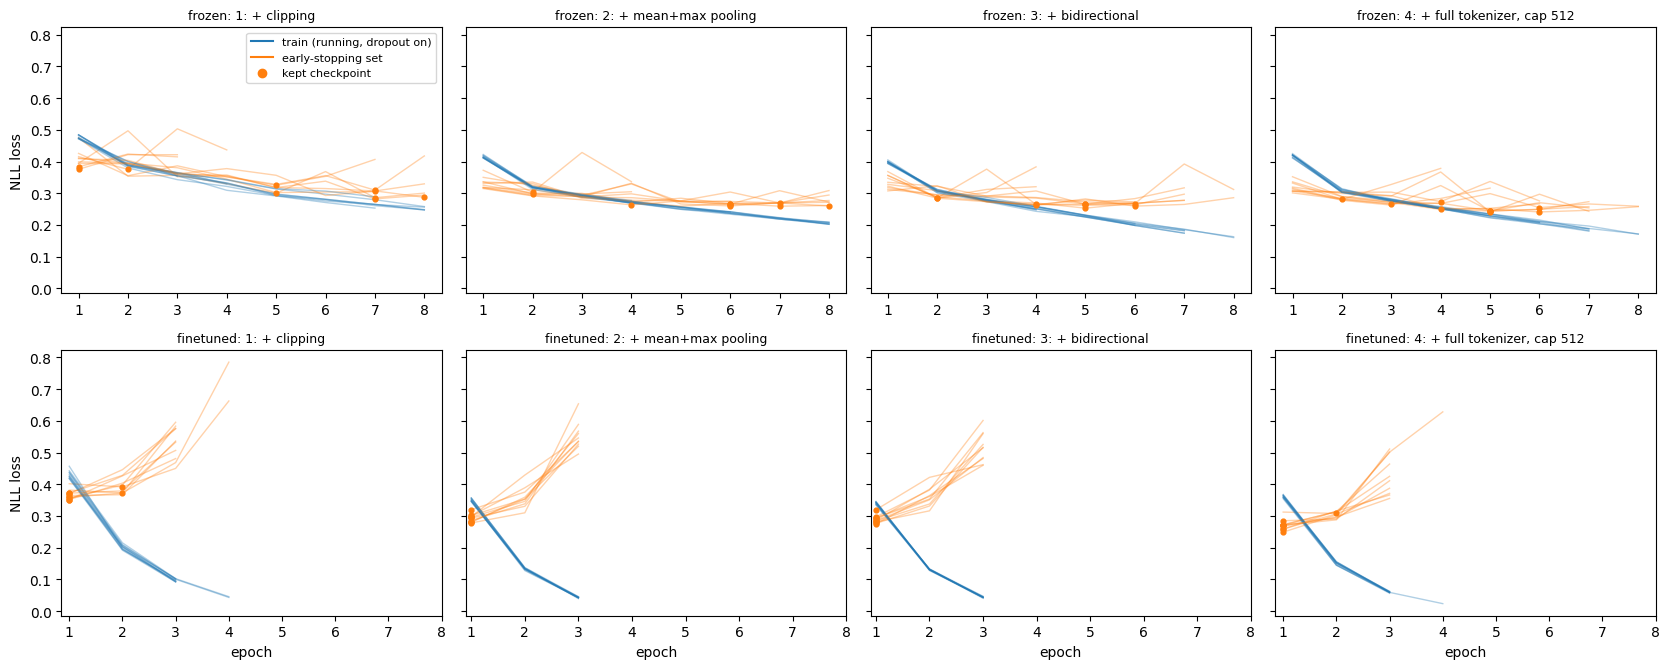

Bayesian correlated t-test (ROPE = 0.005). Rows 0-7: each step vs the step before (B = the newer step). Rows 8-9: step 0 vs step 4 (all changes together). Rows 10-15: LSTM steps 3 and 4 vs the pools (B = the LSTM).


,System A,System B,Mean A,Mean B,Mean Diff (B - A),Posterior SD,P(A > B),P(Tie),P(B > A),Decision (>=80%)
0,P2: lstm_ft300_frozen,P2: lstm_ft300_frozen_clip,0.8608,0.8732,0.0124,0.0183,0.1831,0.1642,0.6527,Inconclusive / Borderline
1,P2: lstm_ft300_frozen_clip,P2: lstm_ft300_frozen_clip_meanmax,0.8732,0.8914,0.0182,0.0118,0.0404,0.1057,0.8539,P2: lstm_ft300_frozen_clip_meanmax > P2: lstm_...
2,P2: lstm_ft300_frozen_clip_meanmax,P2: lstm_ft300_frozen_clip_meanmax_bi,0.8914,0.8942,0.0028,0.0053,0.0881,0.5701,0.3418,Inconclusive / Borderline
3,P2: lstm_ft300_frozen_clip_meanmax_bi,P2: lstm_ft300_frozen_clip_meanmax_bi_fulltok512,0.8942,0.8995,0.0054,0.0055,0.0469,0.4278,0.5253,Inconclusive / Borderline
4,P2: lstm_ft300_finetuned,P2: lstm_ft300_finetuned_clip,0.8672,0.8698,0.0026,0.0096,0.2247,0.3716,0.4037,Inconclusive / Borderline
5,P2: lstm_ft300_finetuned_clip,P2: lstm_ft300_finetuned_clip_meanmax,0.8698,0.8949,0.0251,0.0099,0.0071,0.0298,0.9631,P2: lstm_ft300_finetuned_clip_meanmax > P2: ls...
6,P2: lstm_ft300_finetuned_clip_meanmax,P2: lstm_ft300_finetuned_clip_meanmax_bi,0.8949,0.8970,0.0021,0.0033,0.0306,0.7682,0.2012,Inconclusive / Borderline
7,P2: lstm_ft300_finetuned_clip_meanmax_bi,P2: lstm_ft300_finetuned_clip_meanmax_bi_fullt...,0.8970,0.9045,0.0075,0.0025,0.0004,0.1708,0.8288,P2: lstm_ft300_finetuned_clip_meanmax_bi_fullt...
8,P2: lstm_ft300_frozen,P2: lstm_ft300_frozen_clip_meanmax_bi_fulltok512,0.8608,0.8995,0.0387,0.0214,0.0354,0.0389,0.9257,P2: lstm_ft300_frozen_clip_meanmax_bi_fulltok5...
9,P2: lstm_ft300_finetuned,P2: lstm_ft300_finetuned_clip_meanmax_bi_fullt...,0.8672,0.9045,0.0373,0.0088,0.0005,0.0021,0.9975,P2: lstm_ft300_finetuned_clip_meanmax_bi_fullt...


In [19]:
# ---- 1. One table: every step of both ladders (step 0 = the Task 4 system) ----
def ladder_systems(ladder: str) -> OrderedDict:
    """Step label -> system name, from step 0 (Task 4) to step 4."""
    step0, _ = TASK4B_LADDERS[ladder]
    out = OrderedDict([("0: Task 4 LSTM (no clipping)", step0)])
    for step in TASK4B_STEPS:
        out[TASK4B_STEP_LABELS[step]] = task4b_system_name(ladder, step)
    return out

def load_lstm_runs(system_name: str) -> list:
    return [json.loads((results_folder / system_name / f"seed-{seed}" / "results.json").read_text(encoding="utf-8"))
            for seed in my_seeds]

rows = []
for ladder in TASK4B_LADDERS:
    for label, system_name in ladder_systems(ladder).items():
        runs = load_lstm_runs(system_name)
        acc = np.array([v for run in runs for v in run["accuracies"].values()])
        best_epochs = np.array([v for run in runs for v in run["best_epochs"].values()])
        hist = [h for run in runs for f in run["histories"] for h in run["histories"][f]]
        clipped = [h["frac_batches_clipped"] for h in hist if "frac_batches_clipped" in h]
        max_norms = [h["max_grad_norm"] for h in hist if "max_grad_norm" in h]
        nonfinite = sum(h.get("num_nonfinite_grad_batches", 0) for h in hist)
        rows.append({
            "Ladder": ladder,
            "Step": label,
            "Accuracy mean": acc.mean(),
            "Accuracy std": acc.std(ddof=1),
            "Worst fold": acc.min(),
            "Best fold": acc.max(),
            "Best epoch (mean)": best_epochs.mean(),
            "Batches clipped (%)": 100 * np.mean(clipped) if clipped else np.nan,  # over all epochs run
            "Largest grad norm": max(max_norms) if max_norms else np.nan,
            "NaN/inf grad batches": nonfinite if clipped else np.nan,
            "Trainable params": runs[0]["num_trainable_params"],
        })
task4b_table = pd.DataFrame(rows).set_index(["Ladder", "Step"])
print("Task 4b: 10-fold CV accuracy for every step (5 folds x seeds 42 and 67).")
print("For reference: pool frozen fastText 0.8539, pool fine-tuned fastText 0.8981, Project 1 TF-IDF MLP 0.8863.")
display(task4b_table.round(4))

# ---- 2. Learning curves of the new systems: training loss vs early-stopping loss ----
fig, axes = plt.subplots(len(TASK4B_LADDERS), len(TASK4B_STEPS), figsize=(4.2 * len(TASK4B_STEPS), 3.4 * len(TASK4B_LADDERS)),
                         sharey=True, squeeze=False)
for r, ladder in enumerate(TASK4B_LADDERS):
    for c, step in enumerate(TASK4B_STEPS):
        ax = axes[r, c]
        for run in load_lstm_runs(task4b_system_name(ladder, step)):
            for f, hist in run["histories"].items():
                ep = [h["epoch"] for h in hist]
                ax.plot(ep, [h["train_loss"] for h in hist], color="tab:blue", alpha=0.35, lw=1)
                ax.plot(ep, [h["es_loss"] for h in hist], color="tab:orange", alpha=0.35, lw=1)
                best = run["best_epochs"][f]
                ax.scatter([best], [hist[best - 1]["es_loss"]], color="tab:orange", s=12, zorder=3)
        ax.set_title(f"{ladder}: {TASK4B_STEP_LABELS[step]}", fontsize=9)
        ax.set_xticks(range(1, TASK4B_OPT_KWARGS["max_epochs"] + 1))
        if r == len(TASK4B_LADDERS) - 1:
            ax.set_xlabel("epoch")
    axes[r, 0].set_ylabel("NLL loss")
axes[0, 0].legend(handles=[
    plt.Line2D([], [], color="tab:blue", label="train (running, dropout on)"),
    plt.Line2D([], [], color="tab:orange", label="early-stopping set"),
    plt.Line2D([], [], color="tab:orange", marker="o", ls="", label="kept checkpoint"),
], fontsize=8)
plt.tight_layout()
plt.show()

# ---- 3. Bayesian comparisons: each step vs the step before, then the final steps vs the pools ----
for ladder in TASK4B_LADDERS:
    for system_name in ladder_systems(ladder).values():
        all_classifiers[f"P2: {system_name}"] = load_saved_cv_runs(results_folder, system_name)

task4b_comparisons = []
for ladder in TASK4B_LADDERS:
    names = [f"P2: {s}" for s in ladder_systems(ladder).values()]
    task4b_comparisons += list(zip(names[:-1], names[1:]))  # step k-1 vs step k
for ladder in TASK4B_LADDERS:
    names = [f"P2: {s}" for s in ladder_systems(ladder).values()]
    task4b_comparisons.append((names[0], names[-1]))  # step 0 vs step 4: all changes together
for ladder in TASK4B_LADDERS:
    for step in ["clip_meanmax_bi", "clip_meanmax_bi_fulltok512"]:  # fixed in advance, not picked after seeing results
        task4b_comparisons.append(("P2: pool_fasttext300_finetuned", f"P2: {task4b_system_name(ladder, step)}"))
for step in ["clip_meanmax_bi", "clip_meanmax_bi_fulltok512"]:
    task4b_comparisons.append(("P2: pool_fasttext300_frozen", f"P2: {task4b_system_name('frozen', step)}"))

print("Bayesian correlated t-test (ROPE = 0.005). Rows 0-7: each step vs the step before (B = the newer step). Rows 8-9: step 0 vs step 4 (all changes together). Rows 10-15: LSTM steps 3 and 4 vs the pools (B = the LSTM).")
display(compare_pairs_rope(all_classifiers, task4b_comparisons, rope_param=ROPE_SIZE))

### 4b.4 What we found

All numbers are 10-fold CV accuracy (5 folds x seeds 42 and 67), from the table and the Bayesian comparisons above. We call a winner only at a probability of at least 80%, and a difference under 0.5 pp counts as a tie (ROPE).

| Step | Frozen ladder | Change | Fine-tuned ladder | Change |
|---|---|---|---|---|
| 0: Task 4 LSTM | 86.1% | | 86.7% | |
| 1: + clipping | 87.3% | +1.2 pp, inconclusive (P = 0.65) | 87.0% | +0.3 pp, inconclusive |
| 2: + mean+max pooling | 89.1% | **+1.8 pp, better (P = 0.85)** | 89.5% | **+2.5 pp, better (P = 0.96)** |
| 3: + bidirectional | 89.4% | +0.3 pp, inconclusive (P(tie) = 0.57) | 89.7% | +0.2 pp, inconclusive (P(tie) = 0.77) |
| 4: + full tokenizer, cap 512 | 90.0% | +0.5 pp, inconclusive (P = 0.53) | **90.5%** | **+0.8 pp, better (P = 0.83)** |
| Step 0 -> step 4 | | **+3.9 pp (P = 0.93)** | | **+3.7 pp (P = 1.00)** |

**1. Clipping (step 1 vs 0): it fixed the collapses, but did not clearly raise the mean.**
- In Task 4, three frozen runs collapsed: training accuracy suddenly fell by 8-35 pp within one or two epochs (seed 42 folds 0 and 1, seed 67 fold 4). With clipping, **no run collapsed** in any of the 80 Task 4b runs. The worst frozen fold went from 77.7% to 83.7% and the spread across folds from 3.4 to 2.0 pp.
- The mean gain (+1.2 pp frozen, +0.3 pp fine-tuned) is not conclusive: the frozen step-1 runs still vary a lot, because in two folds the early-stopping loss jumped after epoch 1 and the model from epoch 1 was kept.
- **Clipping was not rare.** With a threshold of 1.0, it changed 86% of the updates (frozen) and 56% (fine-tuned); the largest gradient norm was 291. So 1.0 is far below a typical gradient norm here, and clipping acted on most steps, not only on "rare huge steps" as we expected. Because AdamW divides each step by a running average of gradient size, shrinking *every* gradient by a similar factor changes little. What clipping does change is that a single batch with a gradient 100x larger than usual can no longer throw the model off, and those batches are what caused the collapses. A TA could ask why we did not pick a higher threshold: we fixed 1.0 in advance (a common default) and did not tune it.

**2. Mean+max pooling (step 2 vs 1): the biggest single gain, in both ladders.** +1.8 pp (frozen) and +2.5 pp (fine-tuned), both conclusive. So the "last state forgets" problem was real: keeping only the final hidden state threw away most of what the LSTM had read. It also made training calmer: fewer clipped batches (67% and 31%) and largest gradient norms of 14 and 28 instead of 291 and 128. Our explanation: with pooling, the gradient reaches every time step directly instead of only through the last one.

**3. Bidirectional (step 3 vs 2): little or nothing on top of pooling.** +0.3 and +0.2 pp, inconclusive and close to a tie in both ladders. Once every hidden state is pooled, a second reading direction adds little for this task, even though it doubles the LSTM's weights (106k -> 208k).

**4. Full tokenizer, cap 512 (step 4 vs 3): helps, conclusive for the fine-tuned ladder.** +0.8 pp (P = 0.83) fine-tuned, +0.5 pp (inconclusive) frozen. In Task 3 the same tokenizer made the pool *worse* (stopwords dilute an average). For the LSTM it helps, which suggests the LSTM does use the extra words and their order ("not at all", "but"). One caveat: step 4 changes two things at once, the tokenizer and the cap (256 -> 512), chosen so that the same share of reviews (about 10%) is cut. So it reads about the same *share* of each review, but in more detail.

**5. Frozen vs fine-tuned: the same steps help both, and over-fitting is still there.** Both ladders gain about 3.8 pp in total and rank the steps the same way. But the fine-tuned ladder still stops at epoch 1 in almost every run (mean best epoch 1.0-1.2): the 29M embedding weights over-fit as fast as before (training loss near 0.05 by epoch 3, see the learning curves). The frozen LSTM trains for 4-5 epochs and ends only 0.5 pp lower. So the architecture changes did not fix the over-fitting; they made the model better within its first epoch.

**6. The main question: does an LSTM now beat the fine-tuned pool (89.8%)?**
- **Best LSTM: fine-tuned step 4, 90.5%**, +0.6 pp over the pool. The Bayesian test says P(LSTM better) = 0.67, P(tie) = 0.33. **Inconclusive**: it leans towards the LSTM, but not enough to claim a win.
- Frozen step 4 (90.0%) vs fine-tuned pool: **practically equivalent** (P(tie) = 0.81). An LSTM on frozen fastText vectors now matches a pool that fine-tunes 29M embedding weights.
- Against the *frozen* pool (85.4%), both frozen LSTMs win clearly (+4.0 and +4.6 pp, P = 1.00). With the same frozen vectors, reading in order beats averaging.
- It is also the most stable system we have: std 0.4 pp, worst fold 89.8%, which is the pool's *mean*.
- Cost: step 4 took about 18 minutes of GPU training for 10 folds (fine-tuned), against about 8 for the Task 4 LSTM.

**So why did the first LSTM lose?** Mostly because of how it summarised the review (last state only), not because of the 256-token cut. The check below shows this directly.

**Two limitations of these conclusions.**
- Each step is measured on top of the steps before it (see the intro). For example, we don't know what bidirectionality would add without mean+max pooling.
- The ladder's design was fixed before the runs, but it is still one path through many possible changes. "LSTM step 4 vs pool" is a comparison of one tuned LSTM with one tuned pool; we did not, for example, give the pool the full tokenizer with fine-tuning.

### 4b.5 Did the changes fix the long-review problem from Task 6?

Task 6 found that the Task 4 LSTM lost 8.7 pp to the pool on reviews over 450 words, and concluded that the 256-token cut caused most of the gap. Here we check the same length groups for every step of the fine-tuned ladder, using the saved CV predictions (no retraining). If the cut were the main problem, steps 1-3 (still cut at 256 tokens) should not help much on short reviews.

In [ ]:
# ---- Did the Task 4b changes fix the long-review problem found in Task 6? (saved CV predictions, no retraining) ----
# Reuses cv_predictions, preds, gold and features from the Task 6 cell, so the groups are exactly the same.
ladder_error_systems = OrderedDict([
    ("Pool: fine-tuned fastText", "pool_fasttext300_finetuned"),
    ("0: LSTM B", "lstm_ft300_finetuned"),
    ("1: + clipping", "lstm_ft300_finetuned_clip"),
    ("2: + mean+max", "lstm_ft300_finetuned_clip_meanmax"),
    ("3: + bidirectional", "lstm_ft300_finetuned_clip_meanmax_bi"),
    ("4: + full tokenizer, 512", "lstm_ft300_finetuned_clip_meanmax_bi_fulltok512"),
])
preds_ladder = pd.DataFrame({name: cv_predictions(results_folder, s) for name, s in ladder_error_systems.items()})
assert preds_ladder.index.equals(preds.index)  # same reviews, same order as the Task 6 table
correct_ladder = preds_ladder.eq(gold, axis=0)

ladder_tables = []
for feature in ["Length (words)", "True label"]:
    groups = features[feature]
    t = correct_ladder.groupby(np.asarray(groups), sort=False).mean()
    if hasattr(groups, "categories"):
        t = t.reindex(groups.categories)
    t.index = pd.MultiIndex.from_product([[feature], t.index], names=["Feature", "Group"])
    ladder_tables.append(t)
print("Fine-tuned ladder vs the fine-tuned pool, accuracy per group "
      "(10-fold CV predictions, both seeds pooled; same groups as the Task 6 table):")
display(pd.concat(ladder_tables).round(3))

Fine-tuned ladder vs the fine-tuned pool, accuracy per group (10-fold CV predictions, both seeds pooled; same groups as the Task 6 table):


Pool: fine-tuned fastText  0: LSTM B  1: + clipping  2: + mean+max  3: + bidirectional  4: + full tokenizer, 512
Feature        Group                                                                                                                     
Length (words) 1-150                         0.900      0.880          0.884          0.898               0.900                     0.908
               151-300                       0.896      0.870          0.872          0.896               0.899                     0.906
               301-450                       0.898      0.864          0.861          0.900               0.902                     0.909
               over 450                      0.898      0.810          0.815          0.871               0.871                     0.878
True label     negative                      0.893      0.849          0.857          0.888               0.897                     0.912
               positive                      0.903      0.885          0.882          0.902               0.897                     0.897

**What this shows.**
- **Mean+max pooling (step 2) closed the gap on every review up to 450 words**, although the input was still cut at 256 tokens: 86-88% -> 90%, level with the pool. So on the 90% of reviews that are never cut, the Task 4 LSTM lost because of its last-state summary, not because of the cut. **This corrects our Task 6 conclusion.**
- On reviews over 450 words, pooling recovered 6 of the 8.7 pp. Step 4 (cap 512) adds only 0.7 pp more, and the best LSTM is still 2 pp behind the pool there (87.8% vs 89.8%). The longest reviews are still cut, and that is the one place where the pool, which reads everything, keeps an advantage.
- Step 4 beats the pool by about 1 pp on every group up to 450 words, which is where its overall +0.6 pp comes from.
- The bias towards "positive" that Task 6 found for LSTM B is gone: by step 4 the LSTM is slightly *better* on negative reviews (91.2% vs 89.7%).
- These are pooled predictions over 2 x 24,904 reviews, not a Bayesian test, so differences under 1-2 pp within a column are noise (as in Task 6).

---
# Task 4c: How does the amount of training data affect the LSTM?

**Why.** Task 4 asks whether we looked at data size. In Task 3.2 we did this for embed-and-pool: pretrained vectors helped most when training data was scarce. Here we ask the same for our best LSTM (the Task 4b step-4 model), and whether pretraining matters *more* for the LSTM, which has to learn word order and not only which words are positive or negative.

**Design: the same as the Task 3.2 pool experiment, so the two curves can be compared directly.**
- **Data:** random subsets of the full training set (24,904 reviews) of 2%, 5%, 10%, 25%, 50% and 100%, which gives exactly the Task 3.2 sizes (498, 1,245, 2,490, 6,226, 12,452 and 24,904 reviews).
- **Scored on the 2,000 validation reviews**, as in Task 3.2. These are also the reviews used for early stopping (the kept epoch is the one with the lowest loss on them), so, as in Task 3.2, the numbers are slightly optimistic. This affects the LSTM and the pool curves in the same way, so comparing them is fair; the cross-validation results in Tasks 4 and 4b remain our main evidence.
- **Nested subsets:** each smaller subset is part of every larger one (one fixed random order, seed 0), so along the curve only the *amount* of data changes, not which reviews.
- **Model:** the Task 4b step-4 LSTM (clipping, mean+max pooling, bidirectional, full tokenizer, cap 512), with three embedding setups, as in Task 4: **frozen fastText**, **fine-tuned fastText**, and **trainable random** vectors of the same size and scale. All three get the same subset, initial weights and batch order.
- **Training length:** a small subset has few batches per epoch (2% = 16 batches), so 8 epochs would be only ~130 updates. We divide the maximum number of epochs and the patience by the fraction, with caps (at most 40 epochs, patience at most 8), so every size gets roughly as many updates as the full run. At 100% the settings are exactly those of Task 4b.

**Limits.** One run per point, scored on 2,000 reviews: each accuracy is only precise to about $\pm$1.4 pp (95%). We only read large effects from this, as in Task 3.2. The pool curves use partly different embeddings (fine-tuned GloVe-100d, random 100-d), so compare like with like: frozen fastText with frozen fastText.

**For whoever runs this on Kaggle:** the Task 3.2 cell (it loads `ablation_data`), the Task 4 cell 26 and the Task 4b setup cell (4b.1) must have run first; running the notebook from the top does this, loading the saved results instead of retraining. 18 runs, about 50-70 minutes on a GPU (estimated from the Task 4b epoch times), smallest subsets first. Finished runs are saved and skipped on a rerun. Download `results/sentiment/datasize_*/` afterwards (JSON files only).

### 4c.0 Setup and runs (18 runs: 6 sizes x 3 embedding setups)

In [21]:
# ---- Task 4c settings: everything not listed here is the same as the Task 4b step-4 LSTM ----
DATASIZE_FRACTIONS = recurrent.DATA_SIZE_FRACTIONS  # 2%, 5%, 10%, 25%, 50%, 100% (as in Task 3.2)
DATASIZE_SUBSET_SEED = 0                            # one fixed random order for the nested subsets
DATASIZE_RUN_SEED = my_seeds[0]                     # seed for initial weights and batch order (same for all runs)
DATASIZE_ENC_KWARGS = {**TASK4_ENC_KWARGS, "pooling": "meanmax", "bidirectional": True}  # Task 4b step 4
DATASIZE_SYSTEMS = OrderedDict([
    ("ft300_frozen",        {"embedding_init": "pretrained", "freeze_embeddings": True}),
    ("ft300_finetuned",     {"embedding_init": "pretrained", "freeze_embeddings": False}),
    ("random300_trainable", {"embedding_init": "random",     "freeze_embeddings": False}),
])
DATASIZE_LABELS = {"ft300_frozen": "frozen fastText", "ft300_finetuned": "fine-tuned fastText",
                   "random300_trainable": "trainable random"}

def datasize_system_name(emb: str, fraction: float) -> str:
    return f"datasize_lstm_{emb}_p{round(100 * fraction):03d}"

datasize_train_pairs = list(zip(df_train["text_clean"], df_train["label"]))  # all 24,904 training reviews
datasize_eval_pairs = task4_es_pairs                                        # the 2,000 validation reviews (as in Task 3.2)
datasize_subsets = recurrent.nested_subsets(len(datasize_train_pairs), DATASIZE_FRACTIONS, seed=DATASIZE_SUBSET_SEED)

# What each size gets: number of reviews, label balance and training length
size_rows = []
for fraction, idx in datasize_subsets.items():
    labels = [int(datasize_train_pairs[i][1]) for i in idx]
    opt = recurrent.scaled_opt_kwargs(TASK4B_OPT_KWARGS, fraction)
    size_rows.append({"Fraction": fraction, "Training reviews": len(idx), "Positive (%)": 100 * np.mean(labels),
                      "Batches per epoch": int(np.ceil(len(idx) / opt["batch_size"])),
                      "Max epochs": opt["max_epochs"], "Patience": opt["patience"]})
print(f"Task 4c: subsets of the {len(datasize_train_pairs):,} training reviews; every model is scored on the "
      f"{len(datasize_eval_pairs):,} validation reviews (as in Task 3.2).")
display(pd.DataFrame(size_rows).set_index("Fraction").round(1))

# ---- Run: smallest subsets first, so an interrupted session keeps the cheap runs ----
datasize_runs = OrderedDict()
for fraction, idx in datasize_subsets.items():
    split = recurrent.subset_split(datasize_train_pairs, idx, datasize_eval_pairs)
    for emb, emb_cfg in DATASIZE_SYSTEMS.items():
        datasize_runs[(emb, fraction)] = recurrent.run_cv_system(
            name=datasize_system_name(emb, fraction),
            results_folder=results_folder,
            cv_sets_per_seed=[split],
            seeds=[DATASIZE_RUN_SEED],
            es_pairs=task4_es_pairs,             # early stopping on the 2,000 validation reviews
            tokenizer=fullseq_tokenizer,          # Task 4b step 4: full tokenizer, cap 512
            emb_model=ft300_imdb_fullseq,
            enc_kwargs=DATASIZE_ENC_KWARGS,
            regressor_kwargs=TASK4_REGRESSOR_KWARGS,
            opt_kwargs=recurrent.scaled_opt_kwargs(TASK4B_OPT_KWARGS, fraction),
            num_classes=len(sentiment_outcome_space),
            device=TASK4_DEVICE,
            save_weights=False,
            **emb_cfg,
        )[0]

Task 4c: subsets of the 24,904 training reviews; every model is scored on the 2,000 validation reviews (as in Task 3.2).


,Training reviews,Positive (%),Batches per epoch,Max epochs,Patience
Fraction,,,,,
0.02,498,51.0,16,40,8
0.05,1245,47.9,39,40,8
0.10,2490,49.2,78,40,8
0.25,6226,49.7,195,32,8
0.50,12452,49.8,390,16,4
1.00,24904,50.1,779,8,2


[datasize_lstm_ft300_frozen_p002] seed 42 fold 0: training on cuda


  epoch 01 | train loss 0.6953 acc 0.4799 | early-stop loss 0.6914 acc 0.6345 * | 5s


  epoch 02 | train loss 0.6854 acc 0.6064 | early-stop loss 0.6886 acc 0.5130 * | 2s


  epoch 03 | train loss 0.6814 acc 0.5602 | early-stop loss 0.6800 acc 0.6950 * | 2s


... (189 outputs left out)

  epoch 01 | train loss 0.3724 acc 0.8213 | early-stop loss 0.2775 acc 0.8895 * | 39s


  epoch 02 | train loss 0.1587 acc 0.9427 | early-stop loss 0.3304 acc 0.8680 | 39s


  epoch 03 | train loss 0.0712 acc 0.9784 | early-stop loss 0.3751 acc 0.8770 | 39s


[datasize_lstm_random300_trainable_p100] seed 42 fold 0: best epoch 1/3, fold accuracy 0.8895 (2.0 min)


### 4c.1 Results

The LSTM table, the LSTM minus pool difference at each size (frozen fastText in both, the one embedding setup the two experiments share), the training lengths, and the two sets of curves side by side.

Task 4c: LSTM accuracy on the 2,000 validation reviews (one run per cell, about +-1.4 pp):


Embeddings,frozen fastText,fine-tuned fastText,trainable random,Pretraining gain (fine-tuned - random),Fine-tuning gain (fine-tuned - frozen)
Training reviews,,,,,
498,0.8215,0.7960,0.7435,0.0525,-0.0255
1245,0.8185,0.8105,0.7955,0.0150,-0.0080
2490,0.8545,0.8460,0.8280,0.0180,-0.0085
6226,0.8775,0.8575,0.8250,0.0325,-0.0200
12452,0.8880,0.8825,0.8730,0.0095,-0.0055
24904,0.9015,0.8930,0.8895,0.0035,-0.0085


Same sizes, same validation reviews: LSTM minus pool, frozen fastText in both:


,LSTM - pool (frozen fastText)
Training reviews,
498,0.0205
1245,-0.0070
2490,0.0200
6226,0.0395
12452,0.0460
24904,0.0610


Training length per run (epochs are longer for small subsets, see the setup table):


Embeddings,frozen fastText,fine-tuned fastText,trainable random
Training reviews,,,
498,9/17,5/13,5/13
1245,4/12,3/11,3/11
2490,7/15,2/10,2/10
6226,6/14,1/9,1/9
12452,8/12,1/5,1/5
24904,4/6,1/3,1/3


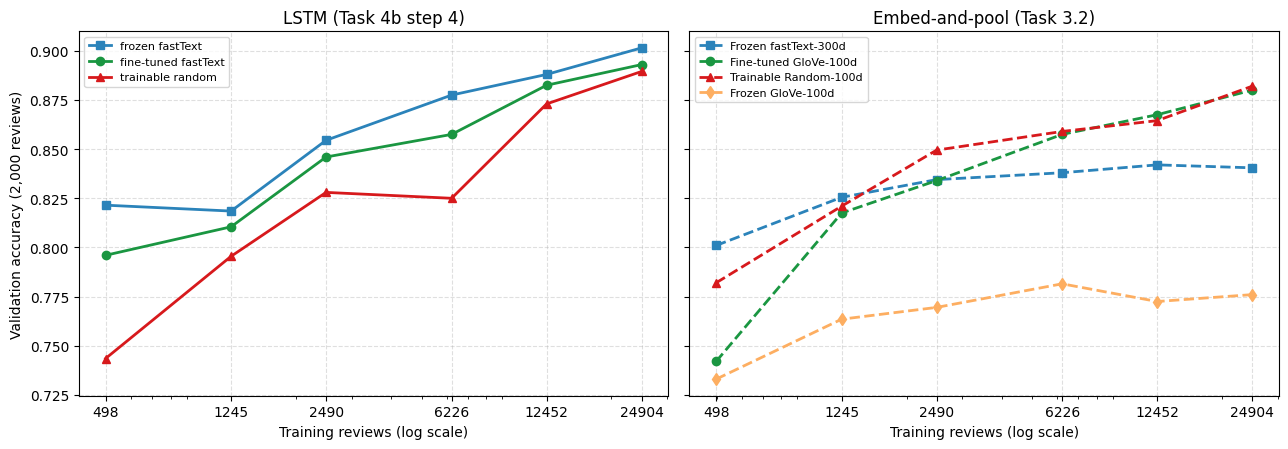

In [22]:
# ---- 1. Table: validation accuracy per embedding setup and training size (same measure as Task 3.2) ----
rows = []
for (emb, fraction), run in datasize_runs.items():
    fold_key = next(iter(run["accuracies"]))
    best, ran = run["best_epochs"][fold_key], run["epochs_run"][fold_key]
    rows.append({
        "Embeddings": DATASIZE_LABELS[emb], "Fraction": fraction,
        "Training reviews": len(datasize_subsets[fraction]),
        "Accuracy": run["accuracies"][fold_key],
        "Best epoch / run": f"{best}/{ran}",
        # best epoch = the last allowed epoch: the model might still have been improving
        "Hit epoch cap": best == run["opt_kwargs"]["max_epochs"],
    })
datasize_table = pd.DataFrame(rows)
acc_wide = datasize_table.pivot(index="Training reviews", columns="Embeddings", values="Accuracy")[list(DATASIZE_LABELS.values())]
acc_wide["Pretraining gain (fine-tuned - random)"] = acc_wide["fine-tuned fastText"] - acc_wide["trainable random"]
acc_wide["Fine-tuning gain (fine-tuned - frozen)"] = acc_wide["fine-tuned fastText"] - acc_wide["frozen fastText"]
print("Task 4c: LSTM accuracy on the 2,000 validation reviews (one run per cell, about +-1.4 pp):")
display(acc_wide.round(4))

df_pool_size = pd.DataFrame(ablation_data["data_size"]).set_index("n_train")
assert list(df_pool_size.index) == list(acc_wide.index), "the LSTM and pool curves should use the same training sizes"
print("Same sizes, same validation reviews: LSTM minus pool, frozen fastText in both:")
display((acc_wide["frozen fastText"] - df_pool_size["Frozen fastText-300d"]).rename("LSTM - pool (frozen fastText)").round(4).to_frame())

print("Training length per run (epochs are longer for small subsets, see the setup table):")
display(datasize_table.pivot(index="Training reviews", columns="Embeddings", values="Best epoch / run")[list(DATASIZE_LABELS.values())])
if datasize_table["Hit epoch cap"].any():
    print("Runs whose best epoch was the last allowed one (may be under-trained):")
    display(datasize_table[datasize_table["Hit epoch cap"]][["Embeddings", "Training reviews", "Best epoch / run"]])

# ---- 2. Plot: LSTM curves (this experiment) next to the Task 3.2 pool curves, same sizes and same reviews ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for label, marker, color in [("frozen fastText", "s", "#2b83ba"), ("fine-tuned fastText", "o", "#1a9641"),
                             ("trainable random", "^", "#d7191c")]:
    axes[0].plot(acc_wide.index, acc_wide[label], marker=marker, color=color, lw=2, label=label)
axes[0].set_title("LSTM (Task 4b step 4)")
for col, marker, color in [("Frozen fastText-300d", "s", "#2b83ba"), ("Fine-tuned GloVe-100d", "o", "#1a9641"),
                           ("Trainable Random-100d", "^", "#d7191c"), ("Frozen GloVe-100d", "d", "#fdae61")]:
    axes[1].plot(df_pool_size.index, df_pool_size[col], marker=marker, color=color, lw=2, ls="--", label=col)
axes[1].set_title("Embed-and-pool (Task 3.2)")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(acc_wide.index)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.set_xlabel("Training reviews (log scale)")
    ax.grid(True, ls="--", alpha=0.4)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Validation accuracy (2,000 reviews)")
plt.tight_layout()
plt.show()

### 4c.2 What we found

Every number is a single run (seed 42) scored on the 2,000 validation reviews, so each accuracy is only precise to about $\pm$1.4 pp. We only read differences above about 2 pp, or patterns that repeat across sizes. The six points of a curve are not independent (nested subsets, the same scored reviews, the same seed), so "the same sign at every size" is a consistent pattern, not a statistical test.

| Training reviews | Frozen fastText | Fine-tuned fastText | Trainable random | Pretraining gain (fine-tuned - random) | LSTM - pool (frozen fastText) |
|---|---|---|---|---|---|
| 498 (2%) | **82.2%** | 79.6% | 74.4% | +5.3 pp | +2.1 pp |
| 1,245 (5%) | **81.9%** | 81.1% | 79.6% | +1.5 pp | -0.7 pp |
| 2,490 (10%) | **85.5%** | 84.6% | 82.8% | +1.8 pp | +2.0 pp |
| 6,226 (25%) | **87.8%** | 85.8% | 82.5% | +3.3 pp | +4.0 pp |
| 12,452 (50%) | **88.8%** | 88.3% | 87.3% | +1.0 pp | +4.6 pp |
| 24,904 (100%) | **90.2%** | 89.3% | 89.0% | +0.4 pp | +6.1 pp |

**1. Pretraining helps most when data is scarce: yes, and more than for the pool.**
- With 498 reviews, fine-tuned fastText is 5.3 pp above trainable random vectors, and frozen fastText 7.8 pp above. With all 24,904 reviews the pretraining gain is only 0.4 pp, in line with Task 4 (B vs C in cross-validation: +1.0 pp, inconclusive).
- In between it is bumpy (1.0-3.3 pp). The random curve dips at 6,226 reviews (82.5%, below its 2,490 point); with one run per point that dip is most likely noise.
- The pool showed the same direction in Task 3.2 but much weaker: there frozen fastText beat random vectors by 1.9 pp at 498 reviews, and random had caught up by 1,245. The random LSTM needs about 12,000 reviews to get within 1.5 pp of frozen fastText.
- Why: a randomly initialised LSTM has to learn what words mean *and* how to combine them in order, from the same few reviews. Pretrained vectors give it the first part for free.

**2. Frozen vs fine-tuned with little data: frozen is the best setup at every size, and the curves never cross.**
- Frozen fastText is ahead by 0.6-2.6 pp at all six sizes. On its own only the 498 (2.6 pp) and 6,226 (2.0 pp) points pass our 2 pp bar, but the sign is the same everywhere.
- The training logs show why: with 498 reviews the fine-tuned model reaches 100% training accuracy by epoch 8 and early stopping keeps epoch 5, while the frozen model keeps improving until epoch 9. Millions of trainable embedding weights let the model memorise a few hundred reviews instead of learning from them. From 6,226 reviews on, both trainable setups keep epoch 1 (over-fitting starts in epoch 2, as in Task 4b); the frozen one keeps epoch 4-8.
- At full size this run has frozen 0.9 pp ahead, while the Task 4b cross-validation had fine-tuned 0.5 pp ahead (90.5% vs 90.0%, inconclusive). Both are within the noise, so with all the data the two are tied. With less data, frozen is the safer choice, and it is also cheaper: it only trains the LSTM and the classifier.

**3. Is the LSTM more data-hungry than the pool? It depends on the embeddings.**
- **Frozen fastText (the like-for-like comparison): no.** With 498-2,490 reviews the LSTM and the pool are within about 2 pp of each other, and from 6,226 reviews on the LSTM pulls away: +4.0, +4.6, +6.1 pp. The frozen pool stops improving after about 1,000 reviews (82.6% -> 84.1% from 1,245 to 24,904), because an average of fixed vectors has few weights to learn and learns all it can from little data. The LSTM keeps gaining 1-2 pp per doubling: it uses the extra data to learn how word order and context change the sentiment, which a pool cannot do.
- **Trainable random vectors: yes.** Here the LSTM is 2-4 pp *below* the pool up to 6,226 reviews (-3.9, -2.6, -2.2, -3.4 pp) and only overtakes it from 12,452 reviews on (+0.9, +0.8 pp). This is not an exact like-for-like comparison (the LSTM uses 300-d vectors, the pool 100-d), but the gap is large.
- Together: "the LSTM needs more data" is only true without pretrained vectors. Pretrained fastText vectors are what make the LSTM work with a few hundred reviews.

**4. Is the curve still rising at 100%? Yes, for all three setups.** Going from 50% to 100% adds +1.4 pp (frozen), +1.1 pp (fine-tuned) and +1.7 pp (random), and all three also rose from 25% to 50%. Each step on its own is within the noise, but six rises in a row point the same way: more training data would most likely still help this LSTM, by roughly 1 pp per doubling. The trainable pool curves are also still rising (+1.3 and +1.8 pp over the last doubling); only the frozen pool has flattened.

**5. No run hit its epoch cap.** The longest run was 17 of 40 allowed epochs (frozen, 498 reviews), and every run was ended by early stopping. So the scaled training length did not limit any point. The small trainable runs keep a model after very few updates (fine-tuned, 498 reviews: epoch 5 = 80 updates, against 779 at full size) because they over-fit, not because the budget ran out.

**Limitations.**
- The scored reviews are also the early-stopping reviews, so all numbers are slightly optimistic (as in Task 3.2). This affects every curve in the same way.
- One seed and one subset order: we did not measure how much a point would move with another seed. This is why we read only the large or repeated effects above.

**In one sentence (for Task 4.4 and the blog):** with pretrained fastText vectors the LSTM already reaches 82% with 498 reviews and beats the frozen pool at every size from 2,490 reviews on, with the gap growing to 6 pp; with random vectors it needs about 12,000 reviews to match the pool, and pretraining is worth 5-8 pp with 2% of the data but only 0.4 pp with all of it.

---
# Summary: short answers to the "Get to work" questions

**1. Which embedding model, and is it a good choice?** fastText-300d (trained on Wikipedia + news, 830k-word vocabulary).
- Tokenization: our `CoherentImdbTokenizer` follows fastText's conventions (for example "n't" becomes "not", and hyphenated words like "low-budget" are kept).
- Coverage: 99.65% of IMDB tokens are in its vocabulary (0.35% unknown).
- It also beats both GloVe models on every check below.

**2. What does it capture, and what are its limitations?**
- What it captures: good film-domain neighbours (dreadful: terrible, awful; cinematography: camerawork). Positive and negative words are linearly separable (93.8% probe accuracy vs. 87.9% for GloVe-100d). As frozen features it beats GloVe-100d by 7.3 pp in cross-validation (85.4% vs. 78.1%).
- Limitations: antonyms sit close together (cos(good, bad) = 0.83), there is one vector per word whatever the sense ("plot", "star"), all unknown words share one vector, and pooling ignores word order.
- Most troubling for sentiment: antonyms being close, because averaging blurs positive and negative words together.

**3. Embed-and-pool: what matters, and did pretrained embeddings help?**
- What matters most is training the embeddings on the task: +4.4 pp for fastText, +10.8 pp for GloVe-100d. The embedding model also matters when frozen (fastText > GloVe-100d > GloVe-50d).
- Tokenizer, pooling type and classifier size each changed results by about 1.5 pp or less in single runs, so we cannot say they matter.
- Better than last week? Frozen: no (85.4% vs. 88.3% for Project 1's BoW MLP). Fine-tuned fastText: yes, 89.8% vs. 88.6% for the best Project 1 model (P = 0.95).
- Did pretraining add anything? Barely, with the full data: trainable random 100-d embeddings reach 89.7%, practically tied with fine-tuned fastText (P(tie) = 0.83). Pretraining helps clearly only when training data is small.

**4. LSTM (Task 4.4):**
- Embeddings (frozen, fine-tuned, random) made no clear difference: 85.7-86.7%.
- Over-fitting was strong with trainable embeddings, so early stopping keeps epoch 1-2. The frozen LSTM was unstable instead.
- The Task 4 LSTM does not beat embed-and-pool: 86.7% vs. 89.8%, P = 0.99.
- Task 4b (one change at a time): gradient clipping removed the collapsed runs; mean+max pooling over all hidden states gave the biggest gain (+2.5 pp); a bidirectional LSTM added little; the full tokenizer with a 512-token cap added +0.8 pp.
- Best LSTM: 90.5% (fine-tuned fastText, all four changes), +0.6 pp over the best pool, but inconclusive (P = 0.67). With frozen fastText it is practically tied with the fine-tuned pool (90.0%, P(tie) = 0.81).
- So the first LSTM lost mainly because it summarised the review by its last hidden state, not because of the 256-token cut. Over-fitting of the trainable embeddings remains (best epoch is still 1).
- Data size (Task 4c, step-4 LSTM, single runs on 2,000 validation reviews): pretraining is worth 5-8 pp with 498 training reviews but only 0.4 pp with all 24,904. Frozen fastText is the best setup at every size. With frozen fastText the LSTM works even with little data (82% with 498 reviews) and its lead over the frozen pool grows with data (up to +6.1 pp); with random vectors it needs about 12,000 reviews to match the pool. The LSTM curves are still rising at 100%.

**5. Uncertainty (Task 5):**
- Search: one setting at a time on a validation set, then 10-run paired cross-validation for the candidates.
- Variance: reported spread, same folds for every system, Bayesian test with a 0.5 pp ROPE, winners only at P >= 80%.
- Single validation runs are only precise to about $\pm$1.6 pp. The data-size curves (Task 3.2, Task 4c) are single runs, so we only read large or repeated effects from them.

**6. Error analysis (Task 6):**
- Long reviews (over 450 words) are where the Task 4 LSTM fails: -8.7 pp vs. the pool. After Task 4b the gap there is 2 pp, and the LSTM is about 1 pp ahead on all shorter reviews.
- Mixed-opinion reviews are hard for everyone.
- Negation-heavy reviews are not where pooling loses.
- Next steps: handle mixed opinions (hard for every system), reduce the over-fitting of trainable embeddings (e.g. word dropout, a lower learning rate for the embeddings), and read the longest reviews in full.

# Tips

## Pretrained embedding models

We will post a list with some options for you. 

## Features for analysis

Features that you can interpret as an aspect of _complexity_ in light of your task's goals.

- length
- presence of rare/common words, including unknown words
- syntactic features (like parts-of-speech, syntactic complexity, syntactic voice, presence of negation, etc.)
- semantic features (eg, the average similarity of the text to training documents or some curated set of training documents, presence of words in certain semantic classes, etc.)
- task-specific features (eg, 
- model-specific features (eg, predicted label, probability assigned to predicted label, number of parameters or layers or some other model descriptor)